# De la señal de una boya a la rosa espectral del oleaje

**Resumen del cuaderno.** El objetivo es obtener el espectro direccional del oleaje $E(f,\theta)$ y su rosa espectral, primero con una boya y después con imágenes de radar SAR (radar de apertura sintética, *synthetic aperture radar*) de Sentinel-1. Se comparan dos reconstrucciones de la distribución direccional (Fourier truncado y Máxima Entropía) con una verdad conocida simulada, y después un método físico (inversión de la función de transferencia SAR) con ocho imágenes reales, con datos reales de la boya NDBC (Centro Nacional de Datos de Boyas de EE. UU., *National Data Buoy Center*) 46042. Resultados principales: la boya recupera las magnitudes integrales ($H_{m0}$, altura significativa espectral; $T_e$, periodo de energía; potencia) con errores de pocos por ciento, pero solo da 4 números por frecuencia, así que ambos métodos fallan en la forma de la distribución (error L1 (suma de diferencias absolutas) de cerca del 50 %, por motivos opuestos: Fourier demasiado ancho, MEM (método de Máxima Entropía, *maximum entropy method*) demasiado estrecho); el swell sigue una dirección propia y el mar de viento sigue al viento; y el SAR da longitud de onda, periodo, altura y dirección del swell, con una ambigüedad de 180° y sin ver el mar de viento, de modo que SAR y boya se complementan. La altura SAR no está validada aquí con una medida independiente; el cuaderno 05 lo hace con ERA5 (reanálisis atmosférico de quinta generación del Centro Europeo de Predicciones Meteorológicas a Plazo Medio, ECMWF).

**Espectro direccional del oleaje $E(f,\theta)$ a partir de una boya, con un experimento de verdad conocida y datos reales**

**Objetivos de la sesión (unos 75 minutos)**

1. Entender por qué el espectro de la elevación $S(f)$ no contiene la dirección y qué mide de más una boya direccional.
2. Calcular los coeficientes direccionales $a_1, b_1, a_2, b_2$ a partir de espectros cruzados.
3. Reconstruir la distribución direccional $D(f,\theta)$ con dos métodos (Fourier truncado y Máxima Entropía) y medir su error frente a una verdad conocida.
4. Dibujar las tres vistas habituales: espectro polar, rosa direccional de energía y mapa frecuencia-dirección.
5. Calcular indicadores ($H_{m0}$, $T_p$ o periodo de pico, $T_e$, energía por sector, flujo de potencia) y separar mar de viento y mar de fondo (swell).
6. Aplicarlo a una semana de datos reales de una boya pública.
7. Procesar imágenes reales de radar SAR de Sentinel-1 para obtener longitud de onda, dirección y altura del oleaje, y dibujar con ellas la misma rosa espectral.
8. Conectarlo con la operación de parques eólicos marinos y repasar las limitaciones.

| Bloque | Secciones | Tiempo orientativo |
|---|---|---|
| Fundamentos | 1 a 3 | 15 min |
| Experimento controlado | 4 a 9 | 25 min |
| Datos reales de boya | 10 a 11 | 10 min |
| Imágenes de satélite SAR | 12 | 15 min |
| Aplicación, limitaciones y lecturas | 13 a 14 | 10 min |

**Convención de direcciones en todo el notebook:** dirección *de procedencia* náutica, en grados desde el norte y en sentido horario (270° = el oleaje viene del oeste), la misma que se usa para el viento.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/wind_cases/03_rosa_espectral_oleaje.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta y descarga la carpeta `datos/` del repositorio. En un entorno de CPU gratuito de Colab (2 núcleos, sin GPU) el cuaderno completo tarda 41 s medidos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan y, en Colab,
# descarga la carpeta datos/ (unos 22 MB) del repositorio del curso si no está junto al cuaderno.
import importlib.util, os, shutil, subprocess, sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
}  # nombre de importación -> requisito de pip
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], check=True)

REPO = 'https://github.com/fborbon/academy.git'         # repositorio del curso (carpeta neural-networks-1002/wind_cases)
if not Path('datos').exists():
    print('Descargando datos/ del repositorio del curso ...')
    tmp = Path('_repo_curso')
    shutil.rmtree(tmp, ignore_errors=True)
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse', REPO, str(tmp)], check=True)
    subprocess.run(['git', '-C', str(tmp), 'sparse-checkout', 'set', 'neural-networks-1002/wind_cases/datos'], check=True)
    shutil.copytree(tmp / 'neural-networks-1002' / 'wind_cases' / 'datos', 'datos')
    shutil.rmtree(tmp, ignore_errors=True)
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()} | datos/: {len(list(Path('datos').glob('*')))} archivos")

Entorno: Python 3.12.3 | local | CPUs: 8 | datos/: 20 archivos


<!-- toc -->
**Contenido**

* [1. Rosa de oleaje convencional frente a espectro direccional](#1.-Rosa-de-oleaje-convencional-frente-a-espectro-direccional)
* [2. Por qué la FFT de $\eta(t)$ da $S(f)$ pero no la dirección](#2.-Por-qué-la-FFT-de-η%28t%29-da-S%28f%29-pero-no-la-dirección)
* [3. La boya direccional y los coeficientes de Longuet-Higgins](#3.-La-boya-direccional-y-los-coeficientes-de-Longuet-Higgins)
* [4. Experimento controlado: dos sistemas de oleaje con verdad conocida](#4.-Experimento-controlado:-dos-sistemas-de-oleaje-con-verdad-conocida)
  * [Simulación de la boya](#Simulación-de-la-boya)
* [5. De las tres series a $S(f)$ y $a_1, b_1, a_2, b_2$](#5.-De-las-tres-series-a-S%28f%29-y-a1,b1,a2,b2)
* [6. Reconstrucción de $D(f,\theta)$: Fourier truncado frente a Máxima Entropía](#6.-Reconstrucción-de-D%28f,θ%29:-Fourier-truncado-frente-a-Máxima-Entropía)
* [7. Tres formas de dibujar el espectro direccional](#7.-Tres-formas-de-dibujar-el-espectro-direccional)
* [8. Indicadores integrales y error frente a la verdad](#8.-Indicadores-integrales-y-error-frente-a-la-verdad)
  * [¿Es suerte? Repetimos con varias realizaciones](#¿Es-suerte?-Repetimos-con-varias-realizaciones)
* [9. Separar mar de viento y swell](#9.-Separar-mar-de-viento-y-swell)
* [10. Datos reales: boya NDBC 46042 (Monterey, costa de California)](#10.-Datos-reales:-boya-NDBC-46042-%28Monterey,-costa-de-California%29)
* [11. Una semana de datos reales: ¿el mar de viento sigue al viento y el swell no?](#11.-Una-semana-de-datos-reales:-¿el-mar-de-viento-sigue-al-viento-y-el-swell-no?)
* [12. Oleaje desde imágenes de satélite: radar SAR de Sentinel-1](#12.-Oleaje-desde-imágenes-de-satélite:-radar-SAR-de-Sentinel-1)
  * [Prueba con verdad conocida: escena SAR sintética](#Prueba-con-verdad-conocida:-escena-SAR-sintética)
* [13. Para qué sirve todo esto en un parque eólico marino](#13.-Para-qué-sirve-todo-esto-en-un-parque-eólico-marino)
* [14. Limitaciones, y dónde entrarían las GNN y las PINN](#14.-Limitaciones,-y-dónde-entrarían-las-GNN-y-las-PINN)

*Para saltar a una sección usa el índice del panel lateral izquierdo: en JupyterLab la pestaña "Table of Contents" y en VS Code la vista "Outline" (se generan solas a partir de los títulos). Los enlaces de esta lista llevan bien a las secciones cercanas, pero JupyterLab no siempre llega a las lejanas porque no dibuja todas las celdas a la vez.*

In [1]:
# Librerías y ajustes generales
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from pathlib import Path

t_inicio = time.time()
np.random.seed(0)                    # semilla global (además usamos generadores con semilla propia)
G, RHO = 9.81, 1025.0                # gravedad [m/s2] y densidad del agua de mar [kg/m3]
DATOS = Path("datos")                # carpeta con la copia local de los datos reales

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
# Colores fijos por entidad (siempre los mismos en todas las figuras)
C_VERDAD, C_FOURIER, C_MEM = "black", "#e07b28", "#2a6fdb"
C_VIENTO, C_MARV, C_SWELL = "#555555", "#3a9d5d", "#8e44ad"

~/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "



## 1. Rosa de oleaje convencional frente a espectro direccional

Una **rosa de oleaje convencional** es un histograma: para muchos estados de mar (por ejemplo cada hora durante años) se cuenta cuántas veces la altura significante $H_s$ cae en cada intervalo y la dirección media en cada sector. Cada estado de mar aporta **un solo punto** (una altura, una dirección).

Un **espectro direccional** describe **un único estado de mar** (unos 20 a 60 minutos) con toda su estructura: cuánta varianza de la superficie hay en cada frecuencia $f$ y en cada dirección $\theta$:

$$
E(f,\theta) = S(f)\,D(f,\theta), \qquad \int_0^{2\pi} D(f,\theta)\,d\theta = 1 .
$$

* $S(f)$ [m²/Hz] es el espectro de frecuencia de la elevación $\eta(t)$.
* $D(f,\theta)$ [1/rad] es la distribución direccional: para cada frecuencia, cómo se reparte la energía por direcciones.
* El momento de orden cero $m_0 = \iint E\,df\,d\theta$ es la varianza de $\eta$, y $H_{m0} = 4\sqrt{m_0}$.

Con una rosa convencional, un mar de viento del oeste y un swell del suroeste que llegan a la vez se mezclan en "una dirección media" que no describe ninguno de los dos. El espectro direccional los separa. Esa diferencia importa en eólica marina: las cargas, el movimiento de los buques de servicio y la desalineación viento-oleaje dependen de cada sistema por separado.


## 2. Por qué la FFT de $\eta(t)$ da $S(f)$ pero no la dirección

Una boya que solo mide la elevación en **un punto** ve, para cada componente de onda, un coseno en el tiempo:

$$
\eta(t) = \sum_j A_j \cos(\mathbf{k}_j\cdot\mathbf{x}_0 - 2\pi f_j t + \varphi_j).
$$

En un punto fijo $\mathbf{x}_0$ la dirección del vector de onda $\mathbf{k}_j$ solo cambia la fase, y la fase es aleatoria. Por tanto el periodograma $|\hat\eta(f)|^2$ es idéntico para cualquier dirección. Lo comprobamos: simulamos el mismo swell viniendo del suroeste (225°) y del noreste (45°) y comparamos los espectros de $\eta$ y de una de las pendientes.

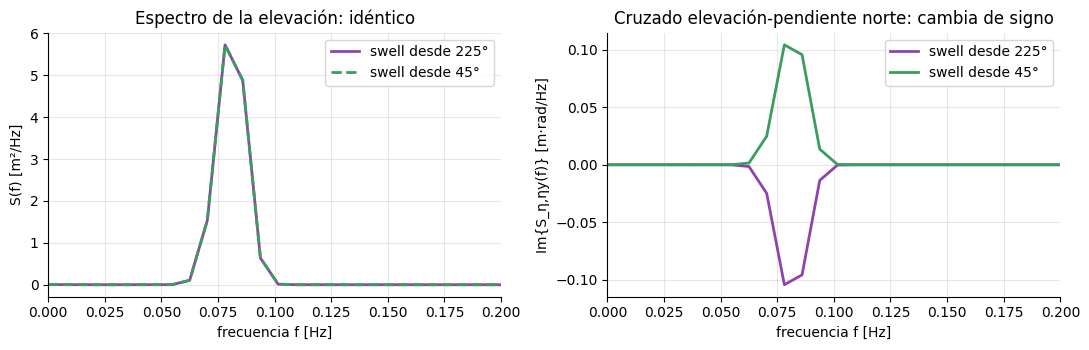

In [2]:
def simula_boya(f, theta_desde, A, fase, t):
    # Suma de ondas lineales en aguas profundas observadas en el punto x=0.
    # Devuelve elevación eta y pendientes este (ex) y norte (ey).
    # theta_desde: dirección de procedencia náutica [rad]; la onda se propaga hacia theta+180.
    k = (2 * np.pi * f) ** 2 / G                         # dispersión en aguas profundas
    kx, ky = -k * np.sin(theta_desde), -k * np.cos(theta_desde)
    eta, ex, ey = (np.zeros_like(t) for _ in range(3))
    for i in range(0, len(f), 1000):                     # por bloques para no saturar la memoria
        s = slice(i, i + 1000)
        psi = -2 * np.pi * f[s, None] * t[None, :] + fase[s, None]
        eta += (A[s, None] * np.cos(psi)).sum(0)
        ex += (-A[s, None] * kx[s, None] * np.sin(psi)).sum(0)
        ey += (-A[s, None] * ky[s, None] * np.sin(psi)).sum(0)
    return eta, ex, ey

fs, duracion = 2.0, 3600.0                 # 2 Hz durante 1 hora
t = np.arange(0, duracion, 1 / fs)
rng = np.random.default_rng(1)
f_demo = np.linspace(0.06, 0.10, 400)
A_demo = 0.05 * np.exp(-((f_demo - 0.08) / 0.008) ** 2)
fase_demo = rng.uniform(0, 2 * np.pi, f_demo.size)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ang, col in [(225, C_SWELL), (45, C_MARV)]:
    eta, ex, ey = simula_boya(f_demo, np.deg2rad(ang) * np.ones_like(f_demo), A_demo, fase_demo, t)
    ff, See = signal.welch(eta, fs, nperseg=256)
    _, Sey = signal.csd(eta, ey, fs, nperseg=256)
    axs[0].plot(ff, See, color=col, lw=2, ls="-" if ang == 225 else "--", label=f"swell desde {ang}°")
    axs[1].plot(ff, Sey.imag, color=col, lw=2, label=f"swell desde {ang}°")
axs[0].set(xlim=(0, 0.2), xlabel="frecuencia f [Hz]", ylabel="S(f) [m²/Hz]", title="Espectro de la elevación: idéntico")
axs[1].set(xlim=(0, 0.2), xlabel="frecuencia f [Hz]", ylabel="Im{S_η,ηy(f)} [m·rad/Hz]", title="Cruzado elevación-pendiente norte: cambia de signo")
for a in axs: a.legend()
plt.tight_layout(); plt.show()

Las dos curvas de la izquierda se superponen: con $\eta(t)$ sola no hay forma de distinguir 225° de 45°. A la derecha, el espectro cruzado entre la elevación y la **pendiente** norte cambia de signo: ahí está la información direccional. Esto es lo que aprovecha una boya direccional.


## 3. La boya direccional y los coeficientes de Longuet-Higgins

Una boya direccional mide tres señales sincronizadas. Hay dos familias de sensores con la misma idea:

* **heave-pitch-roll**: elevación $\eta$ y pendientes de la superficie $\eta_x$ (este) y $\eta_y$ (norte), deducidas de la inclinación del casco y la brújula;
* **desplazamientos**: elevación y desplazamientos horizontales norte y este de una boya que sigue a la partícula de agua (acelerómetros o GPS (sistema de posicionamiento global)).

Con tres señales hay seis espectros: tres autoespectros $C_{\eta\eta}, C_{xx}, C_{yy}$ y tres cruzados. El espectro cruzado tiene parte real (co-espectro $C$) y parte imaginaria (cuadratura $Q$). Para ondas lineales, [Longuet-Higgins et al. (1963)](https://cir.nii.ac.jp/crid/1570291225447611392) mostraron que estas cantidades dan exactamente los **cuatro primeros coeficientes de Fourier** de $D(f,\theta)$:

$$
a_n(f) = \int_0^{2\pi}\cos(n\theta)\,D\,d\theta, \qquad b_n(f) = \int_0^{2\pi}\sin(n\theta)\,D\,d\theta, \qquad n=1,2,
$$

$$
a_1 = \frac{Q_{\eta y}}{\sqrt{C_{\eta\eta}(C_{xx}+C_{yy})}},\quad
b_1 = \frac{Q_{\eta x}}{\sqrt{C_{\eta\eta}(C_{xx}+C_{yy})}},\quad
a_2 = \frac{C_{yy}-C_{xx}}{C_{xx}+C_{yy}},\quad
b_2 = \frac{2\,C_{xy}}{C_{xx}+C_{yy}} .
$$

(Con $\theta$ náutico de procedencia, $\cos\theta$ es la componente norte y $\sin\theta$ la este. El signo de $Q$ depende de la convención de la transformada; abajo lo verificamos con una onda de dirección conocida.) En aguas profundas $C_{xx}+C_{yy} = k^2 C_{\eta\eta}$; normalizar con los espectros medidos evita depender de la profundidad.

De estos coeficientes salen magnitudes con significado físico:

* dirección media $\theta_1 = \operatorname{atan2}(b_1, a_1)$ y dispersión direccional $\sigma_1 = \sqrt{2(1 - r_1)}$ con $r_1 = \sqrt{a_1^2+b_1^2}$;
* dirección principal $\theta_2 = \tfrac12\operatorname{atan2}(b_2,a_2)$ y $r_2=\sqrt{a_2^2+b_2^2}$.

**Lo importante:** una boya solo entrega **4 números por frecuencia** sobre $D(f,\theta)$. Cualquier forma direccional que dibujemos es una reconstrucción a partir de esos 4 números.

In [3]:
def espectros_boya(eta, ex, ey, fs, nperseg=256):
    # Autoespectros y espectros cruzados por Welch (ventana Hann, solape 50 %)
    kw = dict(fs=fs, nperseg=nperseg)
    f, Czz = signal.welch(eta, **kw)
    _, Cxx = signal.welch(ex, **kw)
    _, Cyy = signal.welch(ey, **kw)
    _, Szx = signal.csd(eta, ex, **kw)
    _, Szy = signal.csd(eta, ey, **kw)
    _, Sxy = signal.csd(ex, ey, **kw)
    return f, Czz, Cxx, Cyy, Szx, Szy, Sxy

def coeficientes_direccionales(Czz, Cxx, Cyy, Szx, Szy, Sxy):
    # a1, b1, a2, b2 de Longuet-Higgins (convención náutica "desde")
    den1 = np.sqrt(Czz * (Cxx + Cyy))
    a1, b1 = Szy.imag / den1, Szx.imag / den1
    a2, b2 = (Cyy - Cxx) / (Cxx + Cyy), 2 * Sxy.real / (Cxx + Cyy)
    return a1, b1, a2, b2

# Verificación del signo con una onda estrecha desde 300°
eta, ex, ey = simula_boya(f_demo, np.deg2rad(300) * np.ones_like(f_demo), A_demo, fase_demo, t)
f_v, *esp = espectros_boya(eta, ex, ey, fs)
a1, b1, a2, b2 = coeficientes_direccionales(*esp)
i = np.argmin(abs(f_v - 0.08))
print(f"a1={a1[i]:.3f}  b1={b1[i]:.3f}  a2={a2[i]:.3f}  b2={b2[i]:.3f}")
print(f"dirección media recuperada: {np.rad2deg(np.arctan2(b1[i], a1[i])) % 360:.1f}° (esperada 300°)")

a1=0.498  b1=-0.863  a2=-0.500  b2=-0.866
dirección media recuperada: 300.0° (esperada 300°)



## 4. Experimento controlado: dos sistemas de oleaje con verdad conocida

Construimos un mar "verdadero" con dos sistemas y luego simulamos lo que mediría una boya. Así podemos medir el error de cada método, cosa imposible con datos reales.

| Sistema | $H_{m0}$ | Frecuencia de pico $f_p$ (periodo de pico $T_p$) | Dirección (desde) | Espectro $S(f)$ | Dispersión $s$ |
|---|---|---|---|---|---|
| Mar de viento | 1,6 m | 0,15 Hz (6,7 s) | 270° | JONSWAP (*Joint North Sea Wave Project*, espectro empírico de mar de viento), $\gamma=3{,}3$ (factor de realce del pico) | 8 (ancha) |
| Swell | 1,4 m | 0,08 Hz (12,5 s) | 225° | JONSWAP, $\gamma=7$ | 30 (estrecha) |

El viento local que genera el mar de viento sopla a $U_{10} = 10$ m/s (velocidad del viento a 10 m de altura) desde 270°.

**Forma espectral (JONSWAP):**
$$
S(f) \propto f^{-5}\exp\!\left[-\tfrac54\left(\tfrac{f_p}{f}\right)^4\right]\gamma^{\exp\left[-\frac{(f-f_p)^2}{2\sigma^2 f_p^2}\right]},\qquad \sigma = 0{,}07\ (f\le f_p),\ 0{,}09\ (f>f_p),
$$
escalada para que $4\sqrt{m_0}$ sea el $H_{m0}$ deseado.

**Dispersión direccional tipo $\cos^{2s}$:**
$$
D(\theta) = C(s)\,\cos^{2s}\!\left(\frac{\theta-\theta_m}{2}\right),
$$
con $C(s)$ tal que la integral sea 1. Una $s$ grande da un haz estrecho (swell que ha viajado lejos), una $s$ pequeña uno ancho (mar de viento joven).

In [4]:
def jonswap(f, hm0, fp, gamma):
    # Espectro JONSWAP escalado a un Hm0 dado [m2/Hz]
    f = np.asarray(f, float); S = np.zeros_like(f); m = f > 0
    sig = np.where(f[m] <= fp, 0.07, 0.09)
    S[m] = f[m] ** -5 * np.exp(-1.25 * (fp / f[m]) ** 4) * gamma ** np.exp(-(f[m] - fp) ** 2 / (2 * sig**2 * fp**2))
    ff = np.linspace(0.005, 1.5, 20000)                          # malla fina para normalizar
    sf = np.where(ff <= fp, 0.07, 0.09)
    Sf = ff ** -5 * np.exp(-1.25 * (fp / ff) ** 4) * gamma ** np.exp(-(ff - fp) ** 2 / (2 * sf**2 * fp**2))
    return S * (hm0 / 4) ** 2 / np.trapezoid(Sf, ff)

def cos2s(theta, theta_m, s):
    # Distribución direccional cos^2s normalizada en [0, 2pi) [1/rad]
    D = np.cos((theta - theta_m) / 2) ** (2 * s)
    return D / (D.sum() * (theta[1] - theta[0]))

th = np.deg2rad(np.arange(0, 360, 2.0))      # malla direccional de 2°
dth = th[1] - th[0]
SISTEMAS = {"mar de viento": dict(hm0=1.6, fp=0.15, gamma=3.3, dir=270, s=8),
            "swell":         dict(hm0=1.4, fp=0.08, gamma=7.0, dir=225, s=30)}
U10, DIR_VIENTO = 10.0, 270.0

def E_verdad(f, sistemas=SISTEMAS, solo=None):
    # Espectro direccional verdadero E(f, theta) [m2/(Hz rad)], suma de los sistemas
    E = np.zeros((len(f), len(th)))
    for nombre, p in sistemas.items():
        if solo and nombre != solo: continue
        E += jonswap(f, p["hm0"], p["fp"], p["gamma"])[:, None] * cos2s(th, np.deg2rad(p["dir"]), p["s"])[None, :]
    return E

f_fina = np.linspace(0.02, 0.6, 3000)
E_fina = E_verdad(f_fina)
S_fina = E_fina.sum(1) * dth
print(f"Hm0 total verdadero = {4*np.sqrt(np.trapezoid(S_fina, f_fina)):.3f} m "
      f"(esperado sqrt(1.6²+1.4²) = {np.hypot(1.6, 1.4):.3f} m)")

Hm0 total verdadero = 2.124 m (esperado sqrt(1.6²+1.4²) = 2.126 m)



### Simulación de la boya

Usamos el método de **suma simple**: 20 000 componentes, cada una con una frecuencia distinta, amplitud $A_j=\sqrt{2S(f_j)\Delta f}$, fase aleatoria uniforme y una dirección sorteada de $D(f_j,\theta)$. Así la superficie es gaussiana y no hay componentes de la misma frecuencia que interfieran de forma artificial. Añadimos ruido blanco de medida: 2 cm en la elevación y 0,005 rad en cada pendiente. El registro dura 1 hora a 2 Hz (las boyas operativas suelen registrar entre 20 y 40 minutos).

simulación: 13.4 s, 7200 muestras, Hs ≈ 4·std(η) = 2.15 m


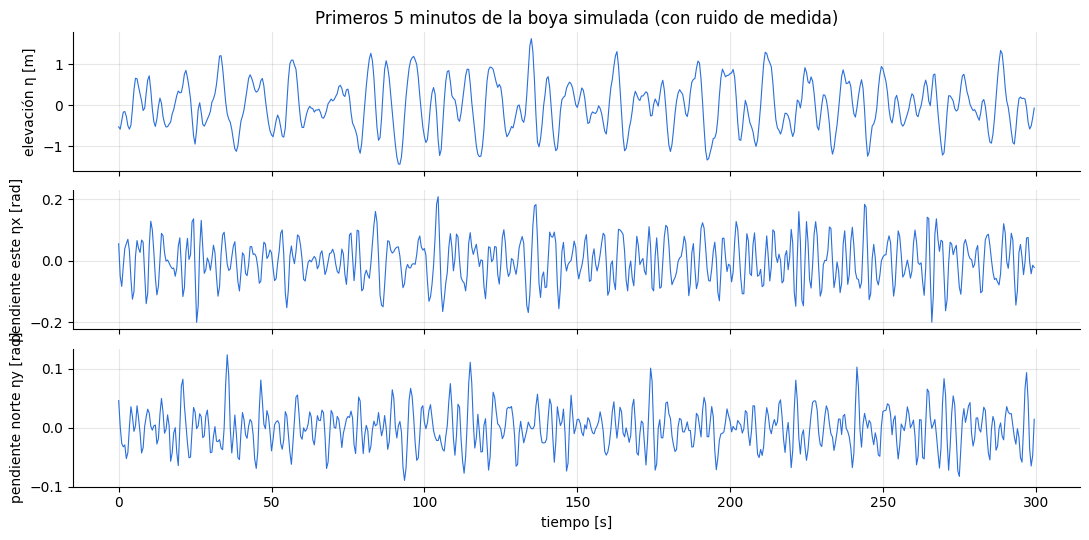

In [5]:
def simula_mar(semilla, n_comp=20000, ruido_eta=0.02, ruido_pend=0.005, sistemas=SISTEMAS):
    r = np.random.default_rng(semilla)
    fmin, fmax = 0.03, 0.5
    df = (fmax - fmin) / n_comp
    f_c = fmin + (np.arange(n_comp) + r.uniform(size=n_comp)) * df     # frecuencias distintas
    Ec = E_verdad(f_c, sistemas)
    S_c = Ec.sum(1) * dth
    cdf = np.cumsum(Ec, 1); cdf /= cdf[:, -1:]                            # CDF direccional por frecuencia
    idx = (cdf < r.uniform(size=(n_comp, 1))).sum(1)
    th_c = th[np.minimum(idx, len(th) - 1)] + r.uniform(-dth / 2, dth / 2, n_comp)
    A = np.sqrt(2 * S_c * df)
    eta, ex, ey = simula_boya(f_c, th_c, A, r.uniform(0, 2 * np.pi, n_comp), t)
    eta += ruido_eta * r.standard_normal(t.size)
    ex += ruido_pend * r.standard_normal(t.size)
    ey += ruido_pend * r.standard_normal(t.size)
    return eta, ex, ey

t0 = time.time()
eta, ex, ey = simula_mar(semilla=42)
print(f"simulación: {time.time()-t0:.1f} s, {t.size} muestras, Hs ≈ 4·std(η) = {4*eta.std():.2f} m")

fig, axs = plt.subplots(3, 1, figsize=(11, 5.5), sharex=True)
m = t < 300
for a, y, lab, u in zip(axs, [eta, ex, ey], ["elevación η", "pendiente este ηx", "pendiente norte ηy"], ["m", "rad", "rad"]):
    a.plot(t[m], y[m], color=C_MEM, lw=0.8); a.set_ylabel(f"{lab} [{u}]")
axs[0].set_title("Primeros 5 minutos de la boya simulada (con ruido de medida)")
axs[-1].set_xlabel("tiempo [s]")
plt.tight_layout(); plt.show()


## 5. De las tres series a $S(f)$ y $a_1, b_1, a_2, b_2$

Estimamos los espectros con el método de Welch: segmentos de 256 muestras (128 s), ventana de Hann y 50 % de solape. La resolución es $\Delta f = 1/128 \approx 0{,}0078$ Hz y cada estimación promedia unos 55 segmentos. Más resolución en frecuencia significa menos promedios y más ruido estadístico: es un compromiso, no hay valor "correcto".

Comparamos con los coeficientes verdaderos, calculados integrando $D$ verdadera.

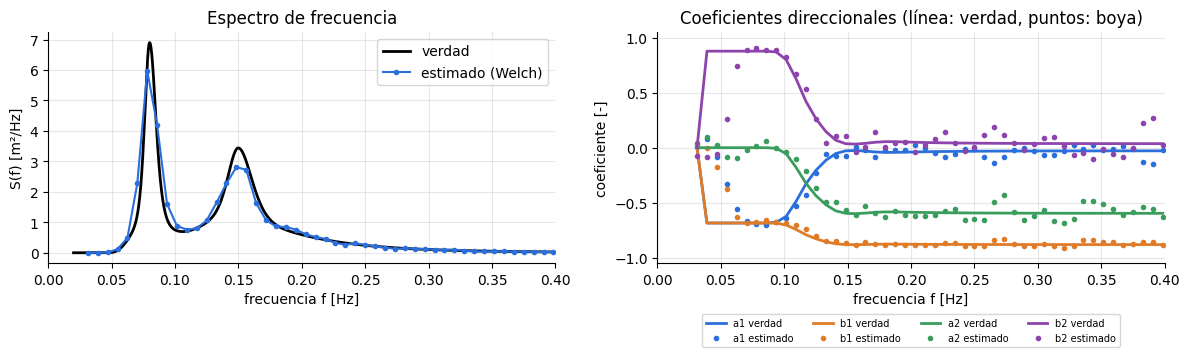

In [6]:
f, Czz, Cxx, Cyy, Szx, Szy, Sxy = espectros_boya(eta, ex, ey, fs)
a1, b1, a2, b2 = coeficientes_direccionales(Czz, Cxx, Cyy, Szx, Szy, Sxy)
banda = (f >= 0.03) & (f <= 0.40)                     # rango útil de frecuencias
f, Czz, a1, b1, a2, b2 = f[banda], Czz[banda], a1[banda], b1[banda], a2[banda], b2[banda]
df_w = f[1] - f[0]

Ev = E_verdad(f)                                        # verdad en la misma malla de frecuencias
Sv = Ev.sum(1) * dth
Dv = Ev / np.maximum(Sv[:, None], 1e-12)
coef_v = {n: (Dv * fun(k * th)).sum(1) * dth for n, fun, k in
          [("a1", np.cos, 1), ("b1", np.sin, 1), ("a2", np.cos, 2), ("b2", np.sin, 2)]}

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(f_fina, S_fina, color=C_VERDAD, lw=2, label="verdad")
axs[0].plot(f, Czz, color=C_MEM, lw=1.5, marker="o", ms=3, label="estimado (Welch)")
axs[0].set(xlim=(0, 0.4), xlabel="frecuencia f [Hz]", ylabel="S(f) [m²/Hz]", title="Espectro de frecuencia")
axs[0].legend()
for (n, est), col in zip([("a1", a1), ("b1", b1), ("a2", a2), ("b2", b2)],
                         ["#2a6fdb", "#e07b28", "#3a9d5d", "#8e44ad"]):
    axs[1].plot(f, coef_v[n], color=col, lw=2, label=f"{n} verdad")
    axs[1].plot(f, est, color=col, lw=0, marker="o", ms=3, label=f"{n} estimado")
axs[1].set(xlim=(0, 0.4), ylim=(-1.05, 1.05), xlabel="frecuencia f [Hz]", ylabel="coeficiente [-]",
           title="Coeficientes direccionales (línea: verdad, puntos: boya)")
axs[1].legend(ncol=4, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); plt.show()

**Lectura:** donde hay energía (de 0,06 a 0,35 Hz) los coeficientes estimados siguen a la verdad con una dispersión de unas centésimas a una décima, que es ruido estadístico de un registro de una hora. Por debajo de 0,06 Hz casi no hay oleaje: ahí el ruido de medida domina y los coeficientes estimados no significan nada (la boya "ve" un mar casi isótropo). En la práctica esas frecuencias se ignoran o se marcan como poco fiables, y lo mismo ocurre en la cola de alta frecuencia con sensores más ruidosos que los simulados.


## 6. Reconstrucción de $D(f,\theta)$: Fourier truncado frente a Máxima Entropía

Con solo cuatro coeficientes hay infinitas funciones $D(\theta)$ compatibles. Hace falta un criterio para elegir una.

**a) Serie de Fourier truncada.** Se usan los términos conocidos y se ponen a cero los demás:
$$
D_F(\theta) = \frac{1}{2\pi}\Big[1 + 2\,(a_1\cos\theta + b_1\sin\theta + a_2\cos2\theta + b_2\sin2\theta)\Big].
$$
Es lineal y transparente, pero muy ancha y puede dar **valores negativos**, que no tienen sentido físico (energía negativa). Existen versiones ponderadas (Longuet-Higgins con pesos 2/3 y 1/6) que garantizan $D\ge0$ a costa de ensanchar aún más.

**b) Máxima Entropía (MEM, Lygre y Krogstad 1986).** Se elige, entre todas las $D$ compatibles con los cuatro coeficientes, la de máxima entropía. El resultado tiene forma cerrada. Con $c_1 = a_1 + i b_1$ y $c_2 = a_2 + i b_2$:
$$
\phi_1 = \frac{c_1 - c_2\,c_1^*}{1-|c_1|^2},\qquad \phi_2 = c_2 - c_1\phi_1,
$$
$$
D_{MEM}(\theta) = \frac{1}{2\pi}\,\frac{1 - \phi_1 c_1^* - \phi_2 c_2^*}{\left|1 - \phi_1 e^{-i\theta} - \phi_2 e^{-2i\theta}\right|^2}.
$$
Es siempre positiva y reproduce exactamente $a_1,\dots,b_2$. Su punto débil conocido: tiende a dar picos **demasiado estrechos** y, a veces, picos espurios cuando dos sistemas comparten frecuencia.

Otro método común es el de Máxima Verosimilitud (MLM, Capon/Isobe): más robusto en algunos casos pero más ancho. No lo implementamos aquí.

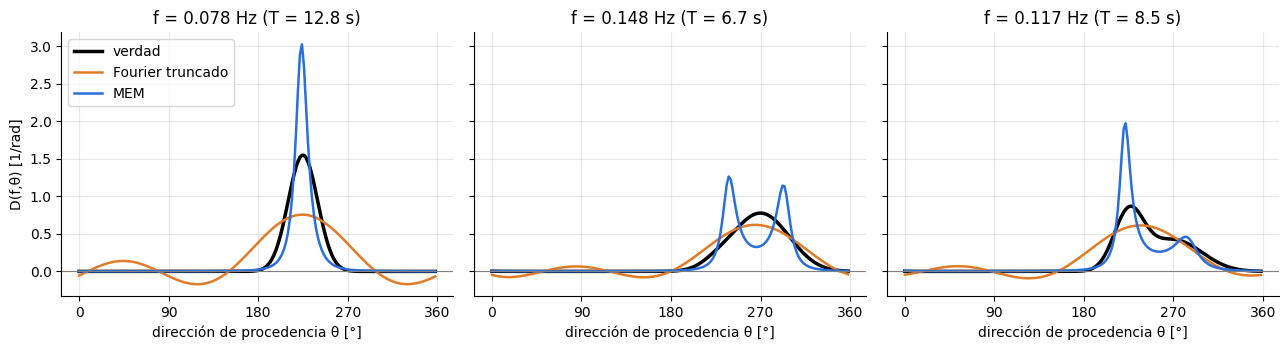

Fourier truncado: 32 % de las celdas (f,θ) son negativas; energía negativa = 14.4 % de la positiva


In [7]:
def D_fourier(a1, b1, a2, b2, theta=th):
    # Fourier truncado de 2.º orden: puede tener valores negativos [1/rad]
    T = theta[None, :]
    return (1 + 2 * (a1[:, None] * np.cos(T) + b1[:, None] * np.sin(T)
                     + a2[:, None] * np.cos(2 * T) + b2[:, None] * np.sin(2 * T))) / (2 * np.pi)

def D_mem(a1, b1, a2, b2, theta=th):
    # Máxima Entropía de Lygre y Krogstad (1986), vectorizada sobre frecuencias [1/rad]
    c1, c2 = a1 + 1j * b1, a2 + 1j * b2
    r1 = np.abs(c1)
    c1 = np.where(r1 > 0.99, c1 * 0.99 / np.maximum(r1, 1e-12), c1)   # evita división por cero si r1 -> 1
    phi1 = (c1 - c2 * np.conj(c1)) / (1 - np.abs(c1) ** 2)
    phi2 = c2 - c1 * phi1
    e1 = np.exp(-1j * theta)[None, :]
    num = (1 - phi1 * np.conj(c1) - phi2 * np.conj(c2)).real[:, None]
    den = np.abs(1 - phi1[:, None] * e1 - phi2[:, None] * e1 ** 2) ** 2
    D = np.maximum(num / (2 * np.pi * den), 0)
    integral = D.sum(1, keepdims=True) * (theta[1] - theta[0])
    uniforme = np.full_like(D, 1 / (2 * np.pi))                        # si los coeficientes son inconsistentes
    return np.where(integral > 0, D / np.where(integral > 0, integral, 1), uniforme)

DF = D_fourier(a1, b1, a2, b2)
DM = D_mem(a1, b1, a2, b2)
EF, EM = Czz[:, None] * DF, Czz[:, None] * DM          # espectros direccionales estimados

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a, fo in zip(axs, [0.08, 0.15, 0.115]):
    i = np.argmin(abs(f - fo))
    a.plot(np.rad2deg(th), Dv[i], color=C_VERDAD, lw=2.5, label="verdad")
    a.plot(np.rad2deg(th), DF[i], color=C_FOURIER, lw=1.8, label="Fourier truncado")
    a.plot(np.rad2deg(th), DM[i], color=C_MEM, lw=1.8, label="MEM")
    a.axhline(0, color="grey", lw=0.8)
    a.set(xlabel="dirección de procedencia θ [°]", title=f"f = {f[i]:.3f} Hz (T = {1/f[i]:.1f} s)", xticks=range(0, 361, 90))
axs[0].set_ylabel("D(f,θ) [1/rad]"); axs[0].legend()
plt.tight_layout(); plt.show()
neg = (EF < 0).sum() / EF.size
print(f"Fourier truncado: {100*neg:.0f} % de las celdas (f,θ) son negativas; "
      f"energía negativa = {100*-EF[EF<0].sum()/EF[EF>0].sum():.1f} % de la positiva")

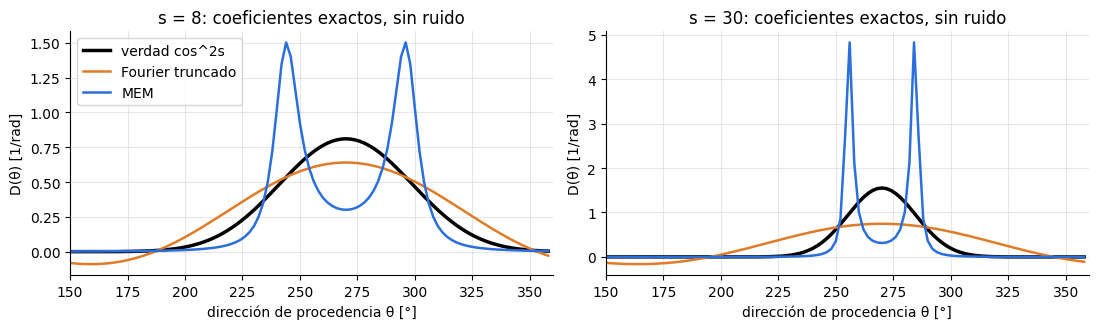

In [8]:
# MEM con coeficientes exactos (sin ruido) de cos^2s centradas en 270°
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for a, s_ in zip(axs, [8, 30]):
    Dt = cos2s(th, np.deg2rad(270), s_)
    c_ex = [np.array([(Dt * fun(k * th)).sum() * dth]) for fun, k in [(np.cos, 1), (np.sin, 1), (np.cos, 2), (np.sin, 2)]]
    a.plot(np.rad2deg(th), Dt, color=C_VERDAD, lw=2.5, label="verdad cos^2s")
    a.plot(np.rad2deg(th), D_fourier(*c_ex)[0], color=C_FOURIER, lw=1.8, label="Fourier truncado")
    a.plot(np.rad2deg(th), D_mem(*c_ex)[0], color=C_MEM, lw=1.8, label="MEM")
    a.set(xlim=(150, 390 - 30), xlabel="dirección de procedencia θ [°]", ylabel="D(θ) [1/rad]",
          title=f"s = {s_}: coeficientes exactos, sin ruido")
axs[0].legend(); plt.tight_layout(); plt.show()

Incluso sin ruido, MEM convierte un $\cos^{2s}$ unimodal en dos picos simétricos: es una propiedad del método (su solución reproduce exactamente $a_1,\dots,b_2$, pero no es la única que lo hace). Con datos reales el ruido a veces "funde" esos picos y a veces los acentúa. Moraleja: **un doble pico estrecho en un espectro MEM no prueba que haya dos sistemas de oleaje**; hay que confirmarlo con la frecuencia, con el viento o con otro método.

**Lectura:**

* En el pico del swell (izquierda) MEM centra bien la dirección pero da un pico **más estrecho y alto** que la verdad; el Fourier truncado es un lóbulo muy ancho con colas negativas.
* En el pico del mar de viento (centro), cuya dispersión verdadera es ancha y con un solo máximo, **MEM inventa dos picos** a ambos lados de 270°. Fourier truncado acierta mejor la forma aquí, aunque con negativos.
* A la derecha, en una frecuencia donde los dos sistemas se solapan, MEM sí sugiere dos lóbulos (uno por sistema), pero con pesos y anchuras incorrectos.

¿El doble pico del centro es culpa del ruido? Lo comprobamos pasando a MEM los coeficientes **exactos** de una distribución $\cos^{2s}$ sin ningún ruido.


## 7. Tres formas de dibujar el espectro direccional

1. **Espectro polar**: el ángulo es la dirección de procedencia (norte arriba, sentido horario), el radio la frecuencia (con el periodo equivalente en las etiquetas) y el color la densidad $E(f,\theta)$.
2. **Mapa cartesiano frecuencia-dirección**: la misma información sin distorsión polar; es el mejor para leer valores y ver valores negativos.
3. **Rosa direccional de energía**: $E(\theta)=\int E(f,\theta)\,df$ agrupada en sectores de 15°, con barras apiladas por bandas de periodo. Es lo más parecido a una rosa convencional pero para **un solo estado de mar**.

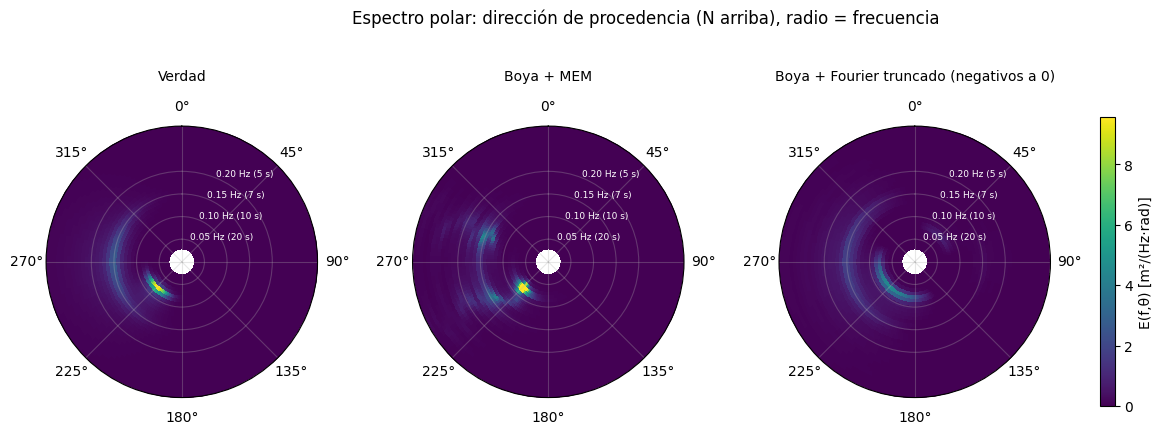

In [9]:
def polar_espectro(ax, f, theta, E, vmax=None, titulo="", fmax=0.3):
    # Espectro polar: ángulo = dirección de procedencia, radio = frecuencia
    dt = theta[1] - theta[0]
    th_b = np.append(theta - dt / 2, theta[-1] + dt / 2)
    df_ = np.gradient(f)
    f_b = np.append(f - df_ / 2, f[-1] + df_[-1] / 2)
    TT, FF = np.meshgrid(th_b, f_b)
    pc = ax.pcolormesh(TT, FF, np.clip(E, 0, None), cmap="viridis", vmin=0, vmax=vmax, shading="flat")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ticks = [0.05, 0.1, 0.15, 0.2]
    ax.set_rticks(ticks)
    ax.set_yticklabels([f"{x:.2f} Hz ({1/x:.0f} s)" for x in ticks], fontsize=6.5, color="white")
    ax.set_rlim(0, fmax); ax.set_rlabel_position(22)
    ax.set_title(titulo, pad=14, fontsize=10)
    return pc

vmax = Ev.max()
fig, axs = plt.subplots(1, 3, figsize=(16, 5), subplot_kw={"projection": "polar"}, gridspec_kw={"wspace": 0.35})
for a, E_, tit in zip(axs, [Ev, EM, EF], ["Verdad", "Boya + MEM", "Boya + Fourier truncado (negativos a 0)"]):
    pc = polar_espectro(a, f, th, E_, vmax=vmax, titulo=tit)
cb = fig.colorbar(pc, ax=axs, shrink=0.75, pad=0.04)
cb.set_label("E(f,θ) [m²/(Hz·rad)]")
fig.suptitle("Espectro polar: dirección de procedencia (N arriba), radio = frecuencia", y=1.0)
plt.show()

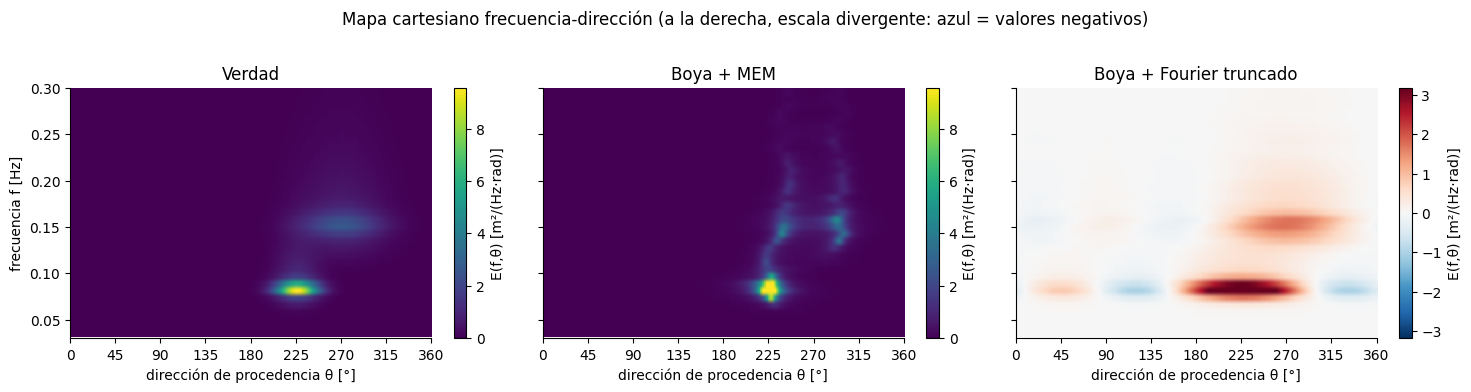

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
extent = [0, 360, f[0], f[-1]]
for a, E_, tit, cmap, lim in [(axs[0], Ev, "Verdad", "viridis", (0, vmax)),
                              (axs[1], EM, "Boya + MEM", "viridis", (0, vmax)),
                              (axs[2], EF, "Boya + Fourier truncado", "RdBu_r", (-vmax / 3, vmax / 3))]:
    im = a.imshow(E_, origin="lower", aspect="auto", extent=extent, cmap=cmap, vmin=lim[0], vmax=lim[1])
    a.set(xlabel="dirección de procedencia θ [°]", title=tit, xticks=range(0, 361, 45), ylim=(0.03, 0.3))
    a.grid(False)
    fig.colorbar(im, ax=a).set_label("E(f,θ) [m²/(Hz·rad)]")
axs[0].set_ylabel("frecuencia f [Hz]")
fig.suptitle("Mapa cartesiano frecuencia-dirección (a la derecha, escala divergente: azul = valores negativos)", y=1.02)
plt.tight_layout(); plt.show()

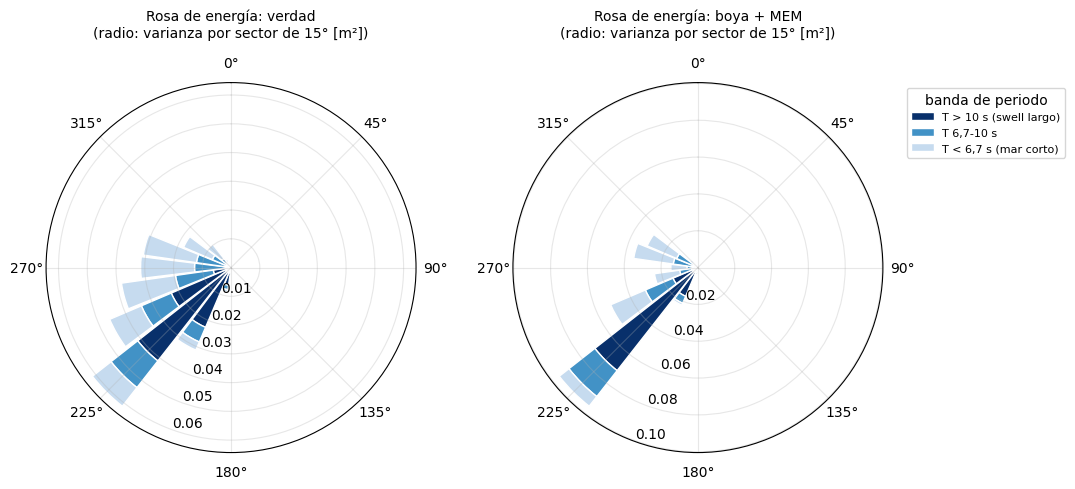

In [11]:
BANDAS = [("T > 10 s (swell largo)", 0.0, 0.10), ("T 6,7-10 s", 0.10, 0.15), ("T < 6,7 s (mar corto)", 0.15, 1.0)]
COL_BANDAS = ["#08306b", "#4292c6", "#c6dbef"]          # una sola gama: oscuro = periodo largo

def rosa_energia(ax, f, theta, E, sector=15, titulo=""):
    # Rosa direccional de energía: varianza [m2] por sector y banda de periodo, barras apiladas
    df_ = np.gradient(f); dt = theta[1] - theta[0]
    sec = (np.round(np.rad2deg(theta) / sector).astype(int) % (360 // sector))
    centros = np.deg2rad(np.arange(0, 360, sector))
    base = np.zeros(len(centros))
    for (lab, f1, f2), col in zip(BANDAS, COL_BANDAS):
        mf = (f >= f1) & (f < f2)
        e_th = (np.clip(E[mf], 0, None) * df_[mf, None]).sum(0) * dt     # varianza por celda direccional
        e_sec = np.bincount(sec, weights=e_th, minlength=len(centros))
        ax.bar(centros, e_sec, width=np.deg2rad(sector) * 0.92, bottom=base, color=col, edgecolor="white", lw=1, label=lab)
        base += e_sec
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_title(titulo + "\n(radio: varianza por sector de 15° [m²])", pad=14, fontsize=10)
    ax.set_rlabel_position(200)
    return base

fig, axs = plt.subplots(1, 2, figsize=(11, 5), subplot_kw={"projection": "polar"})
rosa_energia(axs[0], f, th, Ev, titulo="Rosa de energía: verdad")
rosa_energia(axs[1], f, th, EM, titulo="Rosa de energía: boya + MEM")
axs[1].legend(loc="upper left", bbox_to_anchor=(1.05, 1.0), fontsize=8, title="banda de periodo")
plt.tight_layout(); plt.show()


## 8. Indicadores integrales y error frente a la verdad

A partir de los momentos espectrales $m_n = \iint f^n E(f,\theta)\,df\,d\theta$:

* $H_{m0} = 4\sqrt{m_0}$: altura significante espectral [m].
* $T_p = 1/f_p$: periodo de pico, el de máximo $S(f)$ [s].
* $T_e = T_{m-1,0} = m_{-1}/m_0$: periodo energético [s].
* **Densidad de energía** por unidad de superficie: $\mathcal{E} = \rho g m_0$ [J/m²].
* **Flujo de potencia** por metro de frente de ola, en aguas profundas:
$$
P = \frac{\rho g^2}{64\pi} H_{m0}^2\,T_e \;\approx\; 0{,}49\,H_{m0}^2 T_e \ \ \text{[kW/m]}.
$$

Ojo con una confusión habitual: $\mathcal{E}$ es energía **almacenada** por metro cuadrado de mar (J/m²); $P$ es energía **transportada** por segundo a través de un metro de frente de ola (W/m). Se relacionan mediante la velocidad de grupo $c_g$, que en aguas profundas es la mitad de la velocidad de fase.

La **dirección media por banda** se calcula con los coeficientes ponderados por energía: $\bar\theta = \operatorname{atan2}\!\left(\sum b_1 S\,\Delta f,\ \sum a_1 S\,\Delta f\right)$.

In [12]:
def indicadores(f, theta, E):
    df_ = np.gradient(f); dt = theta[1] - theta[0]
    S = np.clip(E, 0, None).sum(1) * dt
    m0, mm1 = (S * df_).sum(), (S / f * df_).sum()
    hm0, te = 4 * np.sqrt(m0), (mm1 / m0 if m0 > 0 else np.nan)
    return dict(Hm0=hm0, Tp=1 / f[np.argmax(S)], Te=te, Energia_kJm2=RHO * G * m0 / 1e3,
                P_kWm=RHO * G**2 / (64 * np.pi) * hm0**2 * te / 1e3)

def dir_media(f, theta, E, mascara=None):
    # Dirección media de procedencia ponderada por energía [°]
    Ep = np.clip(E, 0, None) if mascara is None else np.clip(E, 0, None) * mascara
    s, c = (Ep * np.sin(theta)).sum(), (Ep * np.cos(theta)).sum()
    return np.rad2deg(np.arctan2(s, c)) % 360

def dif_ang(a, b):
    # Diferencia angular con signo en [-180, 180)
    return (a - b + 180) % 360 - 180      # funciona con números, arrays y Series

ind = pd.DataFrame({"verdad (malla fina)": indicadores(f_fina, th, E_fina),
                    "boya + MEM": indicadores(f, th, EM)}).T
ind["Hm0 error [%]"] = 100 * (ind["Hm0"] / ind.loc["verdad (malla fina)", "Hm0"] - 1)
display(ind.round(2))

filas = []
for lab, f1, f2 in BANDAS:
    mf = ((f >= f1) & (f < f2))[:, None] * np.ones_like(th)[None, :]
    dv, dm, dfo = dir_media(f, th, Ev, mf), dir_media(f, th, EM, mf), dir_media(f, th, EF, mf)
    filas.append(dict(banda=lab, dir_verdad=dv, dir_MEM=dm, error_MEM=dif_ang(dm, dv),
                      dir_Fourier=dfo, error_Fourier=dif_ang(dfo, dv)))
display(pd.DataFrame(filas).set_index("banda").round(1))

,Hm0,Tp,Te,Energia_kJm2,P_kWm,Hm0 error [%]
verdad (malla fina),2.12,12.51,8.47,2.84,18.75,0.00
boya + MEM,2.16,12.80,8.83,2.92,20.13,1.48


,dir_verdad,dir_MEM,error_MEM,dir_Fourier,error_Fourier
banda,,,,,
T > 10 s (swell largo),225.0,224.3,-0.7,224.4,-0.6
"T 6,7-10 s",259.3,256.3,-3.0,256.0,-3.2
"T < 6,7 s (mar corto)",267.8,268.4,0.5,268.6,0.7


In [13]:
# Energía por sector de 45° (porcentaje de la varianza total) y error relativo global del campo E(f,θ)
def energia_sectores(f, theta, E, sector=45):
    df_ = np.gradient(f); dt = theta[1] - theta[0]
    e_th = (np.clip(E, 0, None) * df_[:, None]).sum(0) * dt
    sec = np.round(np.rad2deg(theta) / sector).astype(int) % (360 // sector)
    e = np.bincount(sec, weights=e_th, minlength=360 // sector)
    return pd.Series(100 * e / e.sum(), index=[f"{d}°" for d in range(0, 360, sector)])

display(pd.DataFrame({"verdad [%]": energia_sectores(f, th, Ev), "MEM [%]": energia_sectores(f, th, EM),
                      "Fourier [%]": energia_sectores(f, th, EF)}).T.round(1))

def error_L1(E_est, E_ref):
    return 100 * np.abs(np.clip(E_est, 0, None) - E_ref).sum() / E_ref.sum()
print(f"Error relativo L1 de E(f,θ): MEM {error_L1(EM, Ev):.0f} %   Fourier {error_L1(EF, Ev):.0f} %")

,0°,45°,90°,135°,180°,225°,270°,315°
verdad [%],0.4,0.0,0.0,0.0,3.3,49.2,35.9,11.2
MEM [%],0.4,0.2,0.2,0.3,2.7,58.3,25.4,12.6
Fourier [%],1.1,3.6,2.3,0.3,13.1,34.5,33.4,11.7


Error relativo L1 de E(f,θ): MEM 57 %   Fourier 56 %


**Lectura:** las magnitudes integrales ($H_{m0}$, $T_e$, potencia) se recuperan con errores de pocos por ciento, porque dependen de $S(f)$, que la boya mide bien. Las direcciones medias por banda también salen bien con ambos métodos (son función directa de $a_1, b_1$). Donde ambos métodos fallan es en la **forma** de la distribución: el error L1 del campo completo es del orden del 50 % con los dos, por motivos opuestos (Fourier demasiado ancho y con negativos; MEM demasiado estrecho y con picos partidos). La energía por sectores de 45° lo refleja: MEM concentra de más en el sector del swell y Fourier reparte energía en sectores donde no hay oleaje.


### ¿Es suerte? Repetimos con varias realizaciones

Un único registro de una hora es una muestra aleatoria. Repetimos el experimento con 5 semillas para ver la dispersión de los errores.

In [14]:
t0 = time.time(); res = []
for semilla in range(100, 105):
    e_, x_, y_ = simula_mar(semilla)
    f_r, C_, X_, Y_, zx, zy, xy = espectros_boya(e_, x_, y_, fs)
    c = coeficientes_direccionales(C_, X_, Y_, zx, zy, xy)
    b = (f_r >= 0.03) & (f_r <= 0.40)
    f_r, C_ = f_r[b], C_[b]; c = [ci[b] for ci in c]
    Em_, Ef_, Ev_ = C_[:, None] * D_mem(*c), C_[:, None] * D_fourier(*c), E_verdad(f_r)
    iv, im_ = indicadores(f_fina, th, E_fina), indicadores(f_r, th, Em_)
    sw = ((f_r < 0.10)[:, None]) * np.ones_like(th)[None, :]
    res.append(dict(semilla=semilla, err_Hm0_pct=100 * (im_["Hm0"] / iv["Hm0"] - 1), Tp_est=im_["Tp"],
                    err_Te_pct=100 * (im_["Te"] / iv["Te"] - 1),
                    err_dir_swell=dif_ang(dir_media(f_r, th, Em_, sw), dir_media(f_r, th, Ev_, sw)),
                    err_dir_mar=dif_ang(dir_media(f_r, th, Em_, 1 - sw), dir_media(f_r, th, Ev_, 1 - sw)),
                    L1_MEM=error_L1(Em_, Ev_), L1_Fourier=error_L1(Ef_, Ev_)))
res = pd.DataFrame(res).set_index("semilla")
display(res.round(2)); display(res.agg(["mean", "std"]).round(2))
print(f"(Tp verdadero 12,5 s; {time.time()-t0:.0f} s de cálculo)")

,err_Hm0_pct,Tp_est,err_Te_pct,err_dir_swell,err_dir_mar,L1_MEM,L1_Fourier
semilla,,,,,,,
100,-0.95,12.8,1.49,0.44,1.99,49.07,54.38
101,-2.02,12.8,2.00,-0.57,0.95,51.35,56.52
102,-1.09,12.8,-0.83,1.85,1.21,50.89,53.53
103,-2.32,12.8,-2.56,0.18,-1.55,57.06,54.47
104,-4.66,12.8,-2.70,0.20,-0.18,46.55,51.54


,err_Hm0_pct,Tp_est,err_Te_pct,err_dir_swell,err_dir_mar,L1_MEM,L1_Fourier
mean,-2.21,12.8,-0.52,0.42,0.48,50.99,54.09
std,1.49,0.0,2.20,0.88,1.38,3.88,1.80


(Tp verdadero 12,5 s; 67 s de cálculo)



## 9. Separar mar de viento y swell

El **mar de viento** está todavía forzado por el viento local; el **swell** se generó lejos y viaja libre. Un criterio físico sencillo es la **edad de ola**: una componente con velocidad de fase $c = g/(2\pi f)$ (aguas profundas) puede recibir energía del viento si
$$
\frac{c}{U_{10}\cos(\theta-\theta_w)} < \beta, \qquad \beta \approx 1{,}2\ \text{a}\ 1{,}5 .
$$

Dos variantes:

* **1D (solo frecuencia):** ignorando la dirección, la frecuencia de corte es $f_c = \dfrac{g}{2\pi\beta U_{10}}$. Todo lo que está por encima de $f_c$ (frecuencia de corte) es mar de viento.
* **2D (frecuencia y dirección):** además exige que la componente vaya en la dirección del viento, $\cos(\theta-\theta_w) > 0$. Separa mejor un swell rápido que llega desde otra dirección, pero usa la dirección del viento en la propia definición (lo tendremos en cuenta con los datos reales).

Los métodos operativos más elaborados hacen **particiones del espectro** (buscar las "cuencas" alrededor de cada máximo local de $E(f,\theta)$, tipo watershed) y luego deciden cuáles están forzadas por el viento.



Frecuencia de corte 1D con U10 = 10.0 m/s y β = 1.5: f_c = 0.104 Hz (T = 9.6 s)


Hm0     Tp  dir_media
sistema       método                                
mar de viento MEM + corte 1D  1.64   6.74     264.52
              MEM + corte 2D  1.53   6.74     268.75
              verdad          1.60   6.67     270.00
swell         MEM + corte 1D  1.39  12.80     224.48
              MEM + corte 2D  1.52  12.80     224.99
              verdad          1.40  12.51     225.00

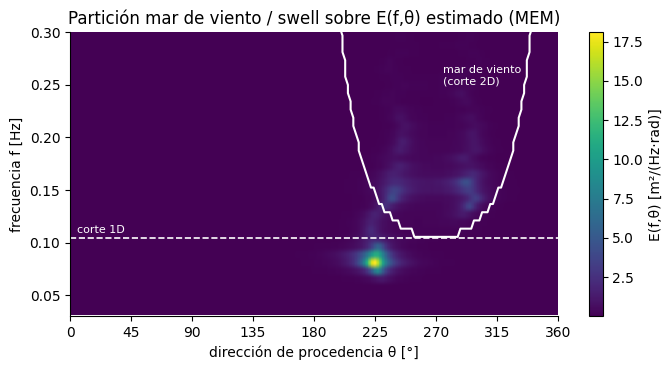

In [15]:
BETA = 1.5

def mascara_mar_viento(f, theta, U10, dir_viento, modo="1D", beta=BETA):
    # 1 donde la componente se considera mar de viento, 0 donde es swell
    c = G / (2 * np.pi * f)[:, None]
    if modo == "1D":
        return (c < beta * U10) * np.ones_like(theta)[None, :]
    proy = U10 * np.cos(theta - np.deg2rad(dir_viento))[None, :]
    return (c < beta * proy).astype(float)

fc = G / (2 * np.pi * BETA * U10)
print(f"Frecuencia de corte 1D con U10 = {U10} m/s y β = {BETA}: f_c = {fc:.3f} Hz (T = {1/fc:.1f} s)")

filas = []
for nombre in SISTEMAS:
    iv = indicadores(f_fina, th, E_verdad(f_fina, solo=nombre))
    filas.append(dict(sistema=nombre, método="verdad", Hm0=iv["Hm0"], Tp=iv["Tp"],
                      dir_media=dir_media(f_fina, th, E_verdad(f_fina, solo=nombre))))
for modo in ["1D", "2D"]:
    mv = mascara_mar_viento(f, th, U10, DIR_VIENTO, modo)
    for nombre, msk in [("mar de viento", mv), ("swell", 1 - mv)]:
        ii = indicadores(f, th, EM * msk)
        filas.append(dict(sistema=nombre, método=f"MEM + corte {modo}", Hm0=ii["Hm0"], Tp=ii["Tp"],
                          dir_media=dir_media(f, th, EM, msk)))
tabla = pd.DataFrame(filas).sort_values(["sistema", "método"]).set_index(["sistema", "método"])
display(tabla.round(2))

fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(EM, origin="lower", aspect="auto", extent=[0, 360, f[0], f[-1]], cmap="viridis")
ax.contour(np.rad2deg(th), f, mascara_mar_viento(f, th, U10, DIR_VIENTO, "2D"), levels=[0.5], colors="white", linewidths=1.5)
ax.axhline(fc, color="white", ls="--", lw=1.2)
ax.text(5, fc + 0.005, "corte 1D", color="white", fontsize=8)
ax.text(275, 0.25, "mar de viento\n(corte 2D)", color="white", fontsize=8)
ax.set(xlabel="dirección de procedencia θ [°]", ylabel="frecuencia f [Hz]", ylim=(0.03, 0.3), xticks=range(0, 361, 45),
       title="Partición mar de viento / swell sobre E(f,θ) estimado (MEM)")
ax.grid(False); fig.colorbar(im, ax=ax).set_label("E(f,θ) [m²/(Hz·rad)]")
plt.tight_layout(); plt.show()

**Lectura:** ambos cortes recuperan $H_{m0}$ y dirección de cada sistema con errores pequeños, porque en este caso los picos están bien separados en frecuencia (0,08 frente a 0,15 Hz). La cola de alta frecuencia del swell se cuenta como mar de viento y viceversa: con sistemas más próximos en frecuencia el error crece. El criterio depende de $\beta$ (umbral de edad de ola) y de un viento que, en la realidad, se mide a pocos metros sobre el mar y hay que corregir a 10 m.


## 10. Datos reales: boya NDBC 46042 (Monterey, costa de California)

**Fuente:** National Data Buoy Center (NDBC, NOAA), ficheros de tiempo real de la estación 46042, descargados el 23-11-2026 de `https://www.ndbc.noaa.gov/data/realtime2/` (datos públicos, sin clave). Guardamos en `datos/` una copia de los últimos 7 días (16 a 23 de noviembre de 2026) para que el notebook funcione sin internet:

| Fichero | Contenido |
|---|---|
| `46042.data_spec` | $C_{11}(f) = S(f)$ [m²/Hz] y la frecuencia de separación que usa NDBC |
| `46042.swdir`, `46042.swdir2` | $\alpha_1$, $\alpha_2$ [°]: direcciones media y principal por frecuencia |
| `46042.swr1`, `46042.swr2` | $r_1$, $r_2$ [-] |
| `46042.spec` | resumen de NDBC (WVHT es la altura significativa, SwH la del swell y WWH la del mar de viento, ...) para contrastar |
| `46042.txt` | meteorología: dirección y velocidad del viento cada 10 min |

NDBC publica los coeficientes en forma polar. La relación con los de Longuet-Higgins es:
$$
a_1 = r_1\cos\alpha_1,\quad b_1 = r_1\sin\alpha_1,\quad a_2 = r_2\cos2\alpha_2,\quad b_2 = r_2\sin2\alpha_2,
$$
y NDBC recomienda $D(f,\theta) = \frac{1}{\pi}\left[\frac12 + r_1\cos(\theta-\alpha_1) + r_2\cos 2(\theta-\alpha_2)\right]$, que es exactamente nuestro Fourier truncado. Usaremos MEM sobre los mismos coeficientes.

La celda de descarga es **opcional**: por defecto lee la copia local.

In [16]:
DESCARGAR = False          # True para bajar los datos más recientes (sobrescribe la copia local)
if DESCARGAR:
    import urllib.request
    try:
        for ext in ["data_spec", "swdir", "swdir2", "swr1", "swr2", "spec", "txt"]:
            urllib.request.urlretrieve(f"https://www.ndbc.noaa.gov/data/realtime2/46042.{ext}", DATOS / f"46042.{ext}")
        print("descarga correcta")
    except Exception as e:
        print("No se pudo descargar, se usa la copia local:", e)

def lee_ndbc_espectral(ruta, con_sep=False):
    # Lee un fichero espectral de NDBC: filas = instantes, columnas = frecuencias
    tiempos, filas, sep, freqs = [], [], [], None
    for linea in open(ruta):
        if linea.startswith("#"): continue
        p = linea.split()
        tiempos.append(pd.Timestamp(*map(int, p[:5])))
        if con_sep: sep.append(float(p[5]))
        pares = re.findall(r"([-\d.]+)\s+\(([\d.]+)\)", linea)
        filas.append([float(v) for v, _ in pares])
        freqs = np.array([float(fr) for _, fr in pares])
    df_ = pd.DataFrame(filas, index=pd.DatetimeIndex(tiempos, name="tiempo_UTC"), columns=freqs).replace(999.0, np.nan)
    df_ = df_[~df_.index.duplicated()].sort_index()
    return (df_, pd.Series(sep, index=pd.DatetimeIndex(tiempos)).sort_index()) if con_sep else df_

C11, SEP = lee_ndbc_espectral(DATOS / "46042.data_spec", con_sep=True)
ALF1, ALF2 = lee_ndbc_espectral(DATOS / "46042.swdir"), lee_ndbc_espectral(DATOS / "46042.swdir2")
R1, R2 = lee_ndbc_espectral(DATOS / "46042.swr1"), lee_ndbc_espectral(DATOS / "46042.swr2")
comunes = C11.index.intersection(ALF1.index).intersection(ALF2.index).intersection(R1.index).intersection(R2.index)
f_r = C11.columns.values
print(f"{len(comunes)} espectros entre {comunes.min()} y {comunes.max()} UTC; {len(f_r)} bandas de {f_r[0]} a {f_r[-1]} Hz")

met = pd.read_csv(DATOS / "46042.txt", sep=r"\s+", skiprows=[1], na_values=["MM", 99.0, 999.0])
met.index = pd.to_datetime(dict(year=met["#YY"], month=met.MM, day=met.DD, hour=met.hh, minute=met.mm))
met = met.sort_index()[["WDIR", "WSPD", "WVHT"]]
resumen = pd.read_csv(DATOS / "46042.spec", sep=r"\s+", skiprows=[1], na_values=["MM"])
resumen.index = pd.to_datetime(dict(year=resumen["#YY"], month=resumen.MM, day=resumen.DD, hour=resumen.hh, minute=resumen.mm))
resumen = resumen.sort_index()

337 espectros entre 2026-11-16 19:20:00 y 2026-11-23 19:10:00 UTC; 46 bandas de 0.033 a 0.485 Hz


In [17]:
# Viento asociado a cada espectro (registro meteorológico más cercano, máx. 20 min) y corrección a 10 m
Z_ANEM = 4.1     # altura aproximada del anemómetro en boyas de 3 m de NDBC [m]; compruébalo en la ficha de la estación
viento = pd.merge_asof(pd.DataFrame(index=comunes), met[["WDIR", "WSPD"]], left_index=True, right_index=True,
                       direction="nearest", tolerance=pd.Timedelta("20min"))
viento["U10"] = viento.WSPD * (10 / Z_ANEM) ** 0.11          # ley potencial sobre el mar (aproximación)

def espectro_real(tiempo, metodo=D_mem):
    # E(f,θ) de un instante a partir de C11, r1, r2, alpha1, alpha2
    S = C11.loc[tiempo].values
    r1, r2 = R1.loc[tiempo].values, R2.loc[tiempo].values
    al1, al2 = np.deg2rad(ALF1.loc[tiempo].values), np.deg2rad(ALF2.loc[tiempo].values)
    ok = np.isfinite(S) & np.isfinite(r1) & np.isfinite(r2) & np.isfinite(al1) & np.isfinite(al2)
    a1, b1 = np.where(ok, r1 * np.cos(al1), 0), np.where(ok, r1 * np.sin(al1), 0)
    a2, b2 = np.where(ok, r2 * np.cos(2 * al2), 0), np.where(ok, r2 * np.sin(2 * al2), 0)
    return np.where(ok, np.nan_to_num(S), 0)[:, None] * metodo(a1, b1, a2, b2)

def particion(ti, E_=None):
    # Separa un espectro real en mar de viento y swell con el corte 1D (solo frecuencia)
    E_ = espectro_real(ti) if E_ is None else E_
    u, wd = viento.U10.get(ti, np.nan), viento.WDIR.get(ti, np.nan)
    if not (np.isfinite(u) and u > 0):
        return {}
    mv = mascara_mar_viento(f_r, th, u, wd, "1D")
    w = np.gradient(f_r)[:, None] * dth
    e_mv, e_sw = (E_ * mv * w).sum(), (E_ * (1 - mv) * w).sum()
    return dict(Hm0_mar=4 * np.sqrt(e_mv), Hm0_swell=4 * np.sqrt(e_sw),
                dir_mar=dir_media(f_r, th, E_, mv) if e_mv > 1e-3 else np.nan,      # sin dirección si apenas hay energía
                dir_swell=dir_media(f_r, th, E_, 1 - mv) if e_sw > 1e-3 else np.nan)

# Instante didáctico: viento moderado (8-15 m/s), mar de viento alineado con él (<30°)
# y swell claramente desalineado (>60°); entre los candidatos, el de mayor mar de viento
cand = []
for ti in viento.dropna().index:
    p = particion(ti)
    if 8 <= viento.U10[ti] <= 15 and abs(dif_ang(p["dir_mar"], viento.WDIR[ti])) < 30 \
            and abs(dif_ang(p["dir_swell"], viento.WDIR[ti])) > 60:
        cand.append((p["Hm0_mar"], ti))
t_sel = max(cand)[1]
print(f"{len(cand)} instantes cumplen el criterio")
E_r = espectro_real(t_sel)
ir = indicadores(f_r, th, E_r)
print(f"Instante elegido: {t_sel} UTC | viento {viento.WDIR[t_sel]:.0f}° a {viento.WSPD[t_sel]:.1f} m/s (U10 ≈ {viento.U10[t_sel]:.1f} m/s)")
print(f"Hm0 = {ir['Hm0']:.2f} m (NDBC WVHT = {resumen.WVHT.asof(t_sel)} m), Tp = {ir['Tp']:.1f} s, "
      f"Te = {ir['Te']:.1f} s, P = {ir['P_kWm']:.0f} kW/m")

/tmp/ipykernel_1954940/3631924340.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  direction="nearest", tolerance=pd.Timedelta("20min"))


5 instantes cumplen el criterio
Instante elegido: 2026-11-19 07:20:00 UTC | viento 220° a 10.0 m/s (U10 ≈ 11.0 m/s)
Hm0 = 3.69 m (NDBC WVHT = 3.8 m), Tp = 13.7 s, Te = 11.5 s, P = 77 kW/m


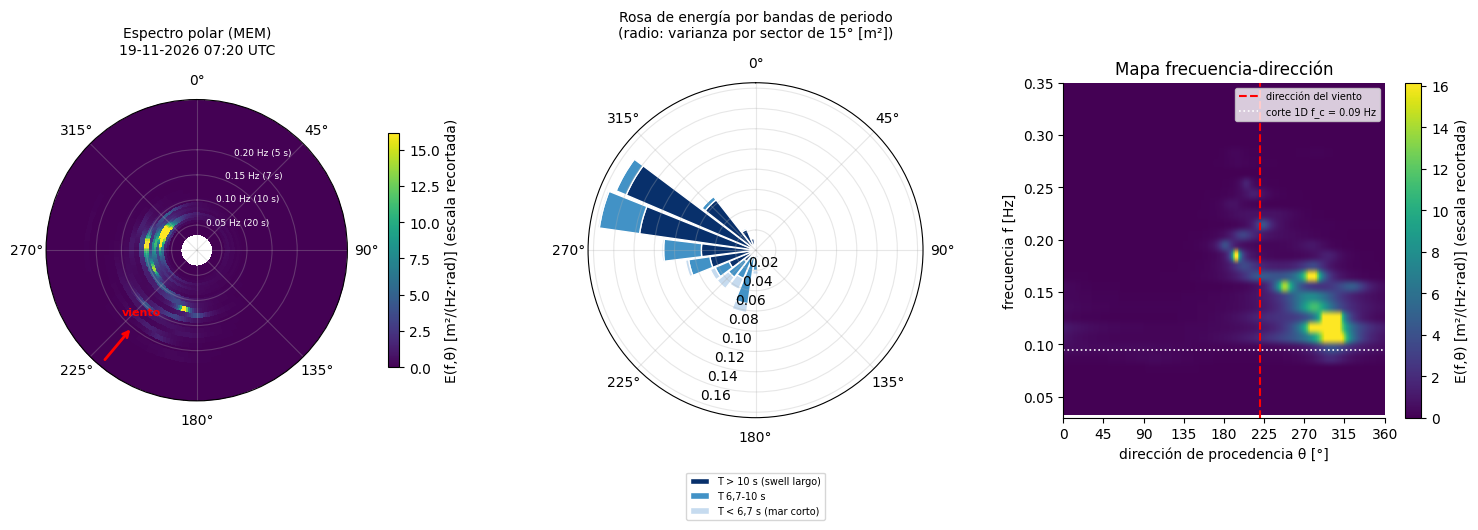

mar de viento : Hm0 = 2.22 m, Tp = 10.0 s, dirección media = 236°
swell         : Hm0 = 2.95 m, Tp = 13.7 s, dirección media = 288°
desalineación swell-viento: 68°
NDBC (su propio algoritmo de separación): {'SwH': 3.6, 'SwP': 13.8, 'SwD': 'WNW', 'WWH': 1.2, 'WWP': 5.6, 'WWD': 'SSW'}


In [18]:
fig = plt.figure(figsize=(15, 5))
ax1 = fig.add_subplot(1, 3, 1, projection="polar")
vmax_r = np.percentile(E_r, 99.5)        # MEM da picos muy finos: recortamos la escala para ver la estructura
pc = polar_espectro(ax1, f_r, th, E_r, vmax=vmax_r, titulo=f"Espectro polar (MEM)\n{t_sel:%d-%m-%Y %H:%M} UTC", fmax=0.3)
ax1.annotate("", xy=(np.deg2rad(viento.WDIR[t_sel]), 0.29), xytext=(np.deg2rad(viento.WDIR[t_sel]), 0.2),
             arrowprops=dict(color="red", arrowstyle="<-", lw=2))
ax1.text(np.deg2rad(viento.WDIR[t_sel]), 0.17, "viento", color="red", ha="center", fontsize=8, fontweight="bold")
fig.colorbar(pc, ax=ax1, shrink=0.7, pad=0.1).set_label("E(f,θ) [m²/(Hz·rad)] (escala recortada)")

ax2 = fig.add_subplot(1, 3, 2, projection="polar")
rosa_energia(ax2, f_r, th, E_r, titulo="Rosa de energía por bandas de periodo")
ax2.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), fontsize=7)

ax3 = fig.add_subplot(1, 3, 3)
im = ax3.imshow(E_r, origin="lower", aspect="auto", extent=[0, 360, f_r[0], f_r[-1]], cmap="viridis", vmin=0, vmax=vmax_r)
ax3.axvline(viento.WDIR[t_sel], color="red", lw=1.5, ls="--", label="dirección del viento")
fcr = G / (2 * np.pi * BETA * viento.U10[t_sel])
ax3.axhline(fcr, color="white", lw=1.2, ls=":", label=f"corte 1D f_c = {fcr:.2f} Hz")
ax3.set(xlabel="dirección de procedencia θ [°]", ylabel="frecuencia f [Hz]", ylim=(0.03, 0.35),
        xticks=range(0, 361, 45), title="Mapa frecuencia-dirección")
ax3.grid(False); ax3.legend(fontsize=7, loc="upper right")
fig.colorbar(im, ax=ax3).set_label("E(f,θ) [m²/(Hz·rad)] (escala recortada)")
plt.tight_layout(); plt.show()

mv = mascara_mar_viento(f_r, th, viento.U10[t_sel], viento.WDIR[t_sel], "1D")
for nom, msk in [("mar de viento", mv), ("swell", 1 - mv)]:
    ii = indicadores(f_r, th, E_r * msk)
    print(f"{nom:14s}: Hm0 = {ii['Hm0']:.2f} m, Tp = {ii['Tp']:.1f} s, dirección media = {dir_media(f_r, th, E_r, msk):.0f}°")
print(f"desalineación swell-viento: {abs(dif_ang(dir_media(f_r, th, E_r, 1 - mv), viento.WDIR[t_sel])):.0f}°")
print("NDBC (su propio algoritmo de separación):",
      resumen.loc[resumen.index.asof(t_sel), ["SwH", "SwP", "SwD", "WWH", "WWP", "WWD"]].to_dict())

**Lectura del instante elegido (19-11-2026 07:20 UTC (tiempo universal coordinado)):** el viento sopla del suroeste (220°) a unos 11 m/s y el mar de viento llega de una dirección parecida (unos 236°), mientras que el swell de periodo largo (unos 14 s) viene del oeste-noroeste (unos 288°): casi 70° de desalineación. El espectro polar y el mapa muestran claramente los dos sistemas.

Las alturas de cada partición **no coinciden** con las de NDBC (swell 2,95 m aquí frente a 3,6 m de NDBC): con $U_{10}\approx 11$ m/s nuestro corte queda en 0,095 Hz (10,5 s) y asigna al mar de viento la energía de unos 10 s, mientras que NDBC usa su propia frecuencia de separación. La altura total sí coincide (3,69 m frente a 3,8 m redondeado). **La partición depende del criterio; la energía total no.**


## 11. Una semana de datos reales: ¿el mar de viento sigue al viento y el swell no?

Repetimos el cálculo para los ~330 espectros de la semana (uno cada 30 minutos). Para no hacer trampa, separamos con el **corte 1D** (solo frecuencia): así la dirección del viento no interviene en la definición del mar de viento y la comparación de direcciones es una prueba independiente.

337 espectros procesados en 0.6 s


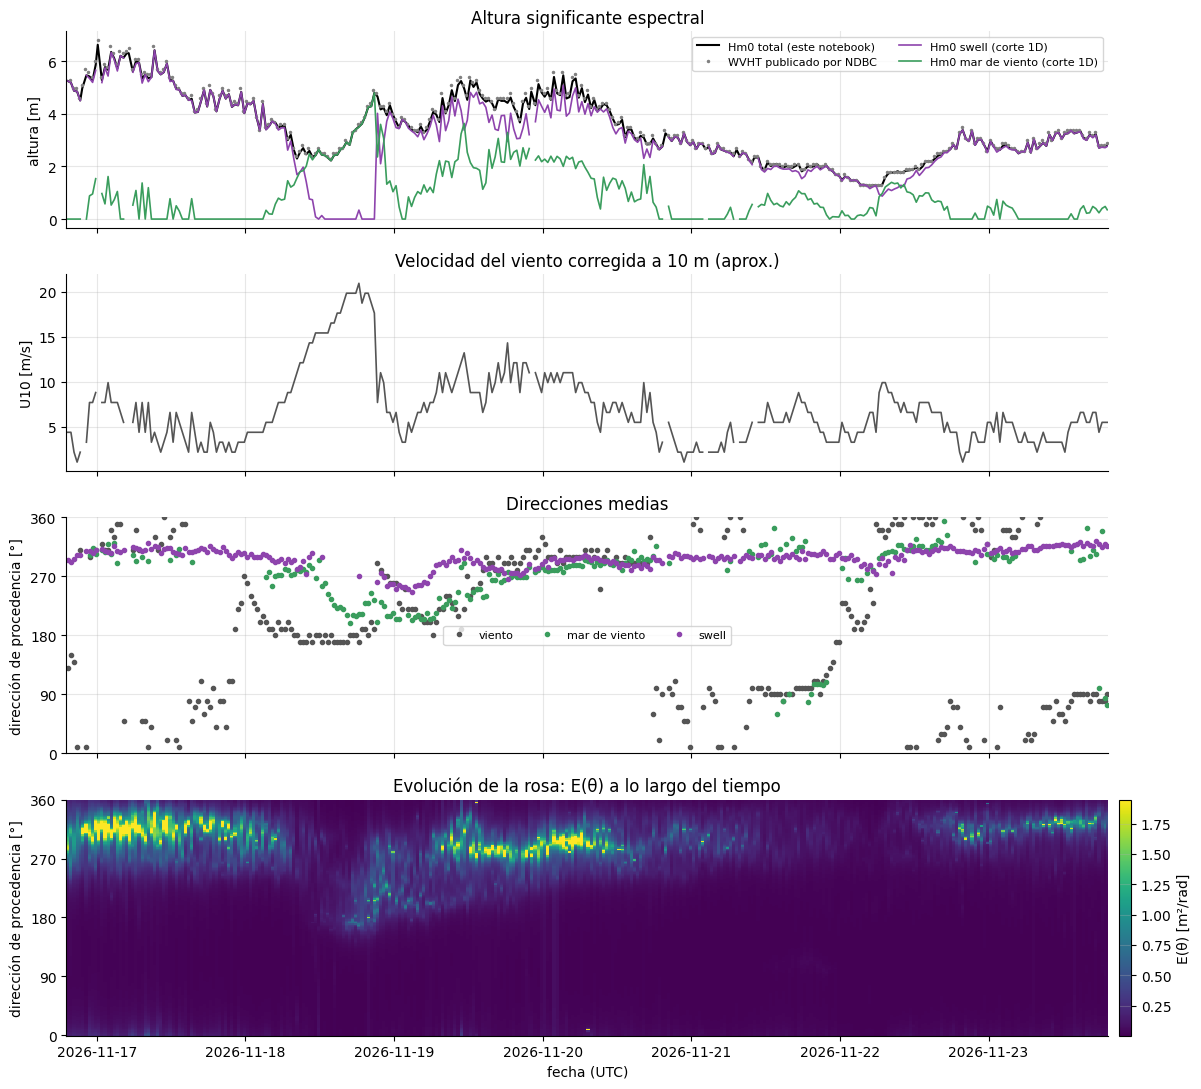

In [19]:
t0 = time.time(); filas, rosa_t = [], []
for ti in comunes:
    E_ = espectro_real(ti)
    ii = indicadores(f_r, th, E_)
    filas.append(dict(tiempo=ti, Hm0=ii["Hm0"], Te=ii["Te"], **particion(ti, E_)))
    rosa_t.append((np.clip(E_, 0, None) * np.gradient(f_r)[:, None]).sum(0))   # E(θ) [m²/rad]
serie = pd.DataFrame(filas).set_index("tiempo").join(viento)
serie["P_kWm"] = RHO * G**2 / (64 * np.pi) * serie.Hm0**2 * serie.Te / 1e3
rosa_t = np.array(rosa_t)
print(f"{len(serie)} espectros procesados en {time.time()-t0:.1f} s")

fig, axs = plt.subplots(4, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [1, 1, 1.2, 1.2]})
axs[0].plot(serie.index, serie.Hm0, color="black", lw=1.5, label="Hm0 total (este notebook)")
axs[0].plot(resumen.index, resumen.WVHT, color="grey", lw=0, marker=".", ms=3, label="WVHT publicado por NDBC")
axs[0].plot(serie.index, serie.Hm0_swell, color=C_SWELL, lw=1.2, label="Hm0 swell (corte 1D)")
axs[0].plot(serie.index, serie.Hm0_mar, color=C_MARV, lw=1.2, label="Hm0 mar de viento (corte 1D)")
axs[0].set(ylabel="altura [m]", title="Altura significante espectral"); axs[0].legend(fontsize=8, ncol=2)
axs[1].plot(serie.index, serie.U10, color=C_VIENTO, lw=1.2)
axs[1].set(ylabel="U10 [m/s]", title="Velocidad del viento corregida a 10 m (aprox.)")
axs[2].plot(serie.index, serie.WDIR, color=C_VIENTO, lw=0, marker="o", ms=3, label="viento")
axs[2].plot(serie.index, serie.dir_mar, color=C_MARV, lw=0, marker="o", ms=3, label="mar de viento")
axs[2].plot(serie.index, serie.dir_swell, color=C_SWELL, lw=0, marker="o", ms=3, label="swell")
axs[2].set(ylabel="dirección de procedencia [°]", ylim=(0, 360), yticks=range(0, 361, 90), title="Direcciones medias")
axs[2].legend(fontsize=8, ncol=3)
im = axs[3].pcolormesh(serie.index, np.rad2deg(th), rosa_t.T, cmap="viridis", shading="nearest",
                       vmax=np.nanpercentile(rosa_t, 99.5))        # recorta valores extremos aislados
axs[3].set(ylabel="dirección de procedencia [°]", yticks=range(0, 361, 90), title="Evolución de la rosa: E(θ) a lo largo del tiempo")
axs[3].grid(False)
cax = axs[3].inset_axes([1.01, 0, 0.012, 1]); fig.colorbar(im, cax=cax).set_label("E(θ) [m²/rad]")
axs[3].set_xlabel("fecha (UTC)")
plt.tight_layout(); plt.show()

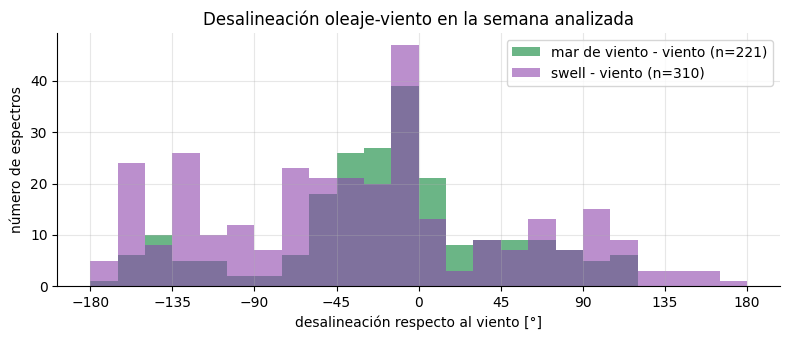

Mediana de |desalineación|: mar de viento 37°, swell 67°
Correlación Hm0 (este notebook) vs WVHT de NDBC: 1.000


/tmp/ipykernel_1954940/1156172653.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  f"{serie.Hm0.corr(resumen.WVHT.reindex(serie.index, method='nearest', tolerance=pd.Timedelta('20min'))):.3f}")


In [20]:
d_mar, d_sw = dif_ang(serie.dir_mar, serie.WDIR).dropna(), dif_ang(serie.dir_swell, serie.WDIR).dropna()
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.arange(-180, 181, 15)
ax.hist(d_mar, bins=bins, color=C_MARV, alpha=0.75, label=f"mar de viento - viento (n={len(d_mar)})")
ax.hist(d_sw, bins=bins, color=C_SWELL, alpha=0.6, label=f"swell - viento (n={len(d_sw)})")
ax.set(xlabel="desalineación respecto al viento [°]", ylabel="número de espectros", xticks=range(-180, 181, 45),
       title="Desalineación oleaje-viento en la semana analizada")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Mediana de |desalineación|: mar de viento {d_mar.abs().median():.0f}°, swell {d_sw.abs().median():.0f}°")
print(f"Correlación Hm0 (este notebook) vs WVHT de NDBC: "
      f"{serie.Hm0.corr(resumen.WVHT.reindex(serie.index, method='nearest', tolerance=pd.Timedelta('20min'))):.3f}")

**Lectura:**

* El **swell** mantiene una dirección propia del oeste-noroeste (290° a 320°) casi toda la semana, fijada por las borrascas lejanas, en mar abierto, que lo generaron, aunque el viento local gire de norte a sur y a este.
* El **mar de viento** sigue al viento cuando éste es moderado o fuerte y estable: el 18 y 19 de noviembre, con viento del sur, el mar de viento gira hacia 180° a 240°. La mediana de su desalineación con el viento (unos 37°) es casi la mitad que la del swell (unos 67°).
* Hay excepciones que también enseñan: cuando el viento rola rápidamente (21 de noviembre, de norte a este) el mar de viento tarda horas en reorientarse, y la energía de periodo corto que queda sigue viniendo del noroeste. Y con viento muy fuerte (18 de noviembre, más de 15 m/s) la frecuencia de corte 1D baja tanto que casi todo el espectro se clasifica como mar de viento: el criterio sencillo tiene límites.
* Nuestro $H_{m0}$ total coincide con el WVHT publicado por NDBC (correlación prácticamente 1), lo que valida la lectura de los ficheros.

Es **una semana en una boya**: sirve para ilustrar el comportamiento, no para sacar estadísticas de diseño, que requieren años de datos.


## 12. Oleaje desde imágenes de satélite: radar SAR de Sentinel-1

Una boya mide el oleaje en **un punto**. Un radar de apertura sintética (SAR) a bordo de un satélite fotografía **unos 20 × 20 km** de mar con una resolución de decenas de metros, y el oleaje largo (swell) aparece como franjas claras y oscuras. De esas franjas se pueden sacar **longitud de onda, dirección y altura**, es decir, un espectro $E(f,\theta)$ que se puede dibujar con las mismas funciones que acabamos de usar con la boya.

**Dato.** Usamos **TenGeoP-SARwv** (Wang et al., 2019, *Geoscience Data Journal* 6(2), 105-115, [doi:10.1002/gdj3.73](https://doi.org/10.1002/gdj3.73)), un conjunto científico y etiquetado a mano de más de 37 000 viñetas del **modo oleaje (Wave Mode, WV) de Sentinel-1A**, polarización VV (emisión y recepción en polarización vertical), año 2016, repartidas por todos los océanos ([doi:10.17882/56796](https://doi.org/10.17882/56796), SEANOE (repositorio francés de datos científicos oceánicos abiertos)). Cada viñeta tiene una etiqueta entre diez fenómenos; aquí solo usamos la clase **F, "Pure Ocean Waves"** (4 900 imágenes). Lo descargamos de forma parcial (los ficheros completos pesan 15 y 16 GB), nos quedamos con las 86 imágenes de la clase F de esa parte, y de ellas con **8** de espectro muy marcado y de zonas distintas, guardadas en `datos/sar_s1_wv_extracto.npz` (4 MB).

* Cada imagen es un GeoTIFF georreferenciado (UTM, proyección universal transversal de Mercator) de 570 × 490 píxeles de unos 38,5 × 41,4 m, de modo que cubre unos 22 × 20 km. Es una imagen de **intensidad** (cuasi-calibrada, media 1), sin la fase compleja del SLC (*single look complex*, imagen compleja de una sola mirada) original.
* Sentinel-1 WV toma una viñeta cada 100 km a lo largo de la órbita, alternando dos subfranjas: **WV1** (incidencia ≈ 23,5°) y **WV2** (≈ 36,5°). La subfranja la necesitaremos para la física de la formación de la imagen.
* **Licencia:** CC BY-NC-SA 4.0 (Creative Commons Atribución, No Comercial, Compartir Igual: uso **no comercial** y compartir igual, con atribución). El extracto de `datos/` hereda esa licencia, así que este material sirve para el curso pero no para un producto comercial. Datos originales: *Contains modified Copernicus Sentinel data (2016)*, ESA (Agencia Espacial Europea).
* **Imágenes de ejemplo del temario.** La página de [Sentinel Success Stories sobre rugosidad del océano Austral](https://sentinels.copernicus.eu/web/success-stories/-/southern-ocean-sea-surface-roughness) muestra dos escenas de Sentinel-1A (3 de mayo y 20 de octubre de 2016) en el mar de Amundsen, pero de **oleaje que se propaga bajo el hielo marino**, no de mar abierto: la altura baja de 1,25 m a 0,4 m a lo largo de unos 14 km dentro del hielo (λ de 230 m) y en la otra hay un swell casi uniforme de 0,5 m (λ de 330 m). La página da los valores pero no explica el método. Es una aplicación distinta a la de este cuaderno (mar abierto, clase 'Pure Ocean Waves'), con la misma física de formación de la imagen. El segundo enlace del temario, un artículo del *Journal of Marine Research* ([Yale EliScholar](https://elischolar.library.yale.edu/cgi/viewcontent.cgi?article=1813&context=journal_of_marine_research)), no se pudo abrir de forma automática (error 403) y **no se ha usado ni resumido aquí**: léelo antes de citarlo.

**Por qué una imagen de radar "ve" las olas.** El radar no mide la altura de la superficie, mide la **rugosidad** (pequeñas ondas capilares de unos 5 cm resonantes con el radar, dispersión de Bragg). El oleaje largo cambia esa rugosidad de tres maneras:

1. **Modulación por inclinación:** la ladera de la ola que mira al radar tiene un ángulo de incidencia local menor y devuelve más energía. Es el efecto dominante para olas que viajan en la dirección de **alcance** (perpendicular a la órbita).
2. **Modulación hidrodinámica:** las olas largas concentran y estiran las ondas cortas. Lo despreciamos aquí.
3. **Agrupamiento por velocidad (*velocity bunching*):** el SAR localiza cada punto por su desplazamiento Doppler, y la velocidad orbital de las olas mueve aparentemente los reflectores a lo largo de la órbita (**acimut**). Es el efecto dominante para olas que viajan en acimut, y vuelve no lineal la imagen si la ola es alta o el satélite está lejos.

En régimen **cuasi-lineal** el espectro de la imagen es el de la superficie multiplicado por una función de transferencia:

$$
P_I(\mathbf k) = |T(\mathbf k)|^2\,F(\mathbf k) + N,\qquad
T = \underbrace{\frac{4i\,k_r\cot\theta_i}{1+\sin^2\theta_i}}_{\text{inclinación (VV)}}\;-\;\underbrace{\frac{R}{V}\,k_a\,\omega\left(\frac{k_r}{|\mathbf k|}\sin\theta_i + i\cos\theta_i\right)}_{\text{agrupamiento por velocidad}},
$$

donde $k_r$ y $k_a$ son las componentes del número de onda en alcance y acimut, $\omega=\sqrt{g|\mathbf k|}$, $\theta_i$ la incidencia, $R/V$ el cociente entre la distancia oblicua y la velocidad del satélite (unos 100 a 115 s en Sentinel-1) y $N$ el suelo blanco de *speckle*. Invirtiendo, $F=(P_I-N)/|T|^2$ da el espectro de la **elevación**, y de $F$ sale la altura: $H_{m0}=4\sqrt{\iint F\,d^2k}$.

**Receta (cada paso es una celda de código):**

1. Normalizar la imagen: $I/\overline{I}_{\text{local}}-1$ (quita la dependencia con el viento local y el ángulo de incidencia).
2. Espectro 2D por el método de Welch (ventanas de 192 × 192 píxeles con 50 % de solape).
3. Restar el suelo de *speckle* (mediana del espectro a número de onda alto).
4. Dividir por $|T|^2$ y quedarnos con longitudes de onda de 120 a 800 m.
5. Convertir $\mathbf k\to(f,\theta)$ con la relación de dispersión en aguas profundas, $k=(2\pi f)^2/g$, y el jacobiano $E(f,\theta)=F\,k\,\frac{dk}{df}$.
6. Aplicar **exactamente las mismas funciones** que a la boya: `polar_espectro`, `rosa_energia`, `indicadores`, `dir_media`.

**Resumen: cómo sale cada magnitud y cuánto fiarse de ella**

| Magnitud | Cómo se calcula | Fiabilidad |
|---|---|---|
| Longitud de onda $\lambda$ | Pico del espectro 2D de la imagen: $\lambda=2\pi/\lvert\mathbf k_p\rvert$ | Alta (es geometría pura), limitada por la resolución del espectro y por la ventana de 120 a 800 m |
| Frecuencia $f$ y periodo $T$ | Dispersión en aguas profundas $\omega^2=g\,k$, es decir $T=\sqrt{2\pi\lambda/g}$ y $f=1/T$ | Alta en aguas profundas (válido para $\lambda<2h$, siendo $h$ la profundidad) |
| Velocidad de fase $c$ y de grupo $c_g$ | $c=\lambda/T=\sqrt{g/k}=gT/2\pi$ y $c_g=c/2$ (aguas profundas) | La misma que $T$; $c_g$ es la velocidad a la que viaja la energía del swell |
| Dirección | Azimut del vector $\mathbf k_p$ en la malla UTM, más la convergencia de meridianos, y $+180°$ para pasar de "hacia dónde viaja" a "de dónde viene" | Buena, pero con **ambigüedad de 180°** (la imagen de intensidad no distingue $\mathbf k$ de $-\mathbf k$) |
| Altura $H_{m0}$ | $(P_I-N)/\lvert T\rvert^2$ integrado: $H_{m0}=4\sqrt{\iint F\,d^2k}$ | **La parte débil.** Validada solo con escenas sintéticas (que usan el mismo modelo). En imágenes reales no hay verdad, y para olas que viajan en acimut subestima por la saturación no lineal |

La tabla de las ocho viñetas incluye estas dos velocidades.

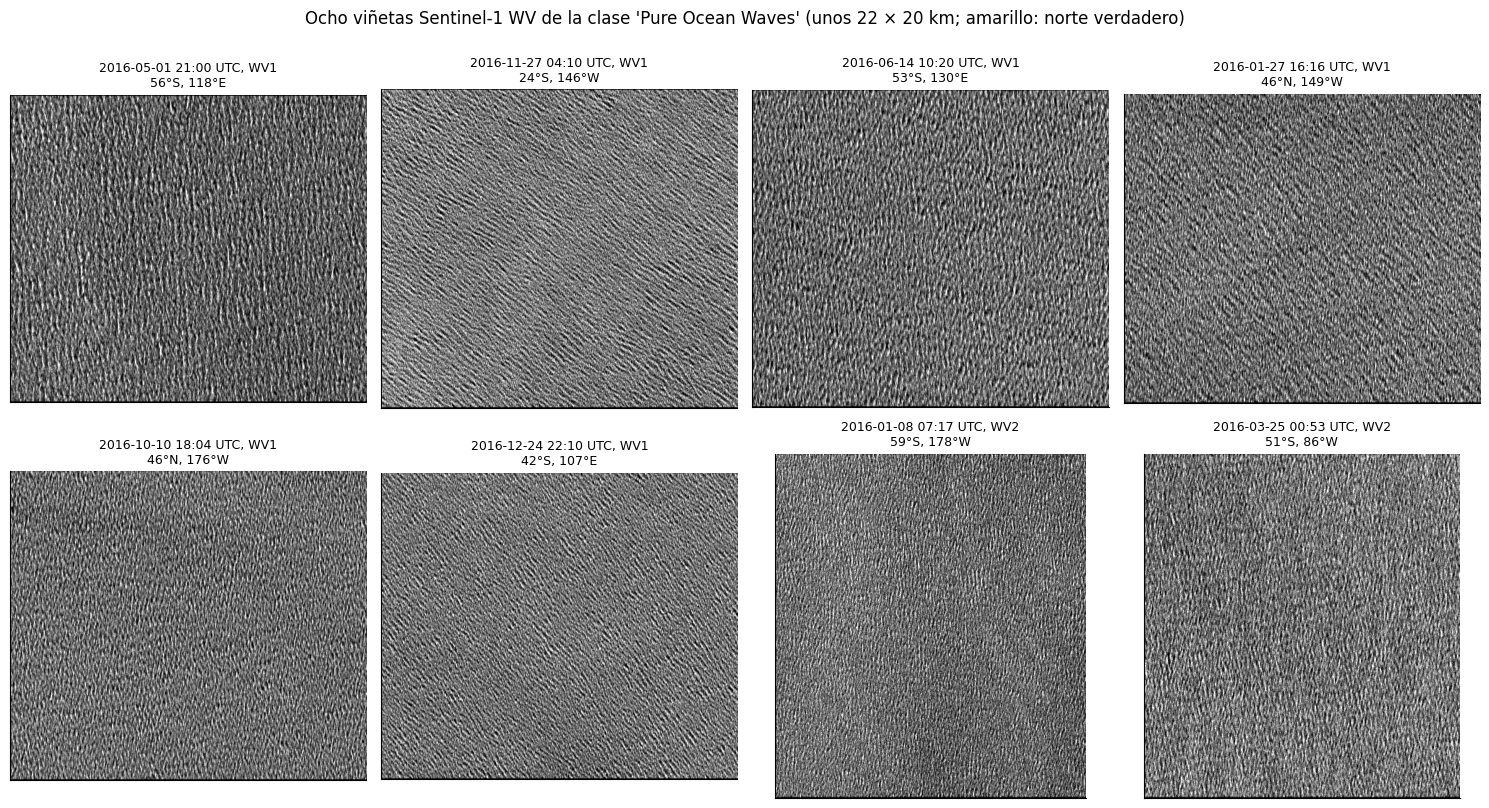

In [21]:
import json
from scipy import ndimage

zsar = np.load(DATOS / "sar_s1_wv_extracto.npz")
meta_sar = json.loads(str(zsar["meta"]))
IMG = [dict(a=zsar[f"img{k}"].astype(float) * 4.5777065690089265e-05,     # intensidad (media ≈ 1)
            ec=zsar[f"ec{k}"], er=zsar[f"er{k}"], **m) for k, m in enumerate(meta_sar)]    # ec, er: metros (E, N) por pixel de columna y de fila

def norte_en_imagen(im, largo=70):
    # Vector (dx, dy) en píxeles de pantalla que apunta al norte verdadero (columnas hacia la derecha, filas hacia abajo)
    n_c, n_r = np.array([0, 1.0]) @ (im["ec"] / np.linalg.norm(im["ec"])), np.array([0, 1.0]) @ (im["er"] / np.linalg.norm(im["er"]))
    return largo * n_c, largo * n_r

fig, axs = plt.subplots(2, 4, figsize=(15, 8.2))
for a_, im in zip(axs.ravel(), IMG):
    lo, hi = np.percentile(im["a"], [1, 99])
    a_.imshow(im["a"], cmap="gray", vmin=lo, vmax=hi); a_.grid(False); a_.set_xticks([]); a_.set_yticks([])
    dx, dy = norte_en_imagen(im)
    a_.annotate("N", xy=(60 + dx, 60 + dy), xytext=(60, 60), color="yellow", fontsize=9, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color="yellow", lw=1.8))
    a_.set_title(f"{im['hora'][:4]}-{im['hora'][4:6]}-{im['hora'][6:8]} {im['hora'][9:11]}:{im['hora'][11:13]} UTC, {im['sub'].upper()}\n"
                 f"{abs(im['lat']):.0f}°{'S' if im['lat'] < 0 else 'N'}, {abs(im['lon']):.0f}°{'E' if im['lon'] > 0 else 'W'}", fontsize=9)
plt.suptitle("Ocho viñetas Sentinel-1 WV de la clase 'Pure Ocean Waves' (unos 22 × 20 km; amarillo: norte verdadero)", y=0.98)
plt.tight_layout(rect=(0, 0, 1, 0.96), h_pad=2.5); plt.show()

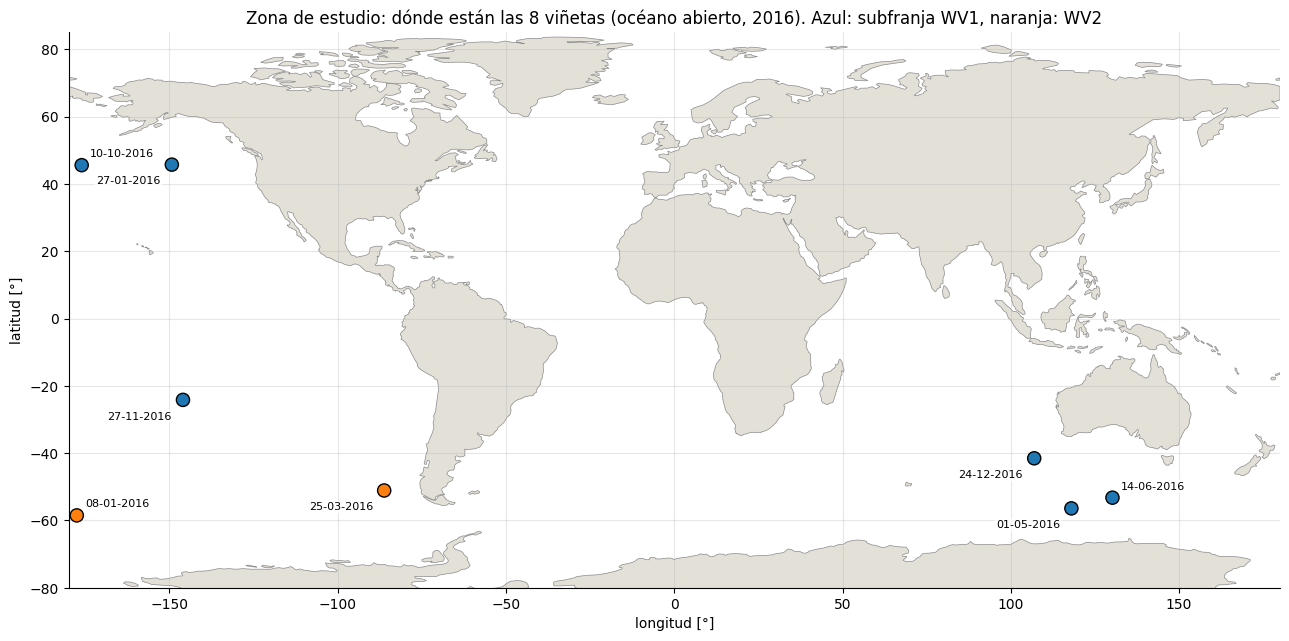

6 de 8 viñetas están en el hemisferio sur; cada viñeta cubre solo unos 22 × 20 km (el punto no está a escala).


In [22]:
def dibuja_mapa(ax, lon, lat, etiquetas=None, colores=None, extra=None, lim=None):
    # Mapa mundial simple (Natural Earth 110 m, dominio público) solo con matplotlib
    gj = json.load(open(DATOS / "ne_110m_land.geojson"))
    for ft in gj["features"]:
        g = ft["geometry"]
        polis = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
        for p in polis:
            xy = np.array(p[0]); ax.fill(xy[:, 0], xy[:, 1], color="#e3e0d8", ec="#8a8a8a", lw=0.5, zorder=1)
    ax.scatter(lon, lat, s=90, c=colores if colores is not None else "#d62728", edgecolor="black", zorder=3)
    if etiquetas is not None:
        for j_, (x_, y_, t_) in enumerate(zip(lon, lat, etiquetas)):
            dx_, dy_, ha_ = (6, 6, "left") if (j_ % 2 == 0 and j_ != 0) else (-8, -14, "right")      # etiquetas alternas para que no se pisen
            ax.annotate(t_, (x_, y_), xytext=(dx_, dy_), ha=ha_, textcoords="offset points", fontsize=8, zorder=2,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    ax.set(xlim=lim[0] if lim else (-180, 180), ylim=lim[1] if lim else (-80, 85), xlabel="longitud [°]", ylabel="latitud [°]")
    ax.set_aspect("equal"); ax.grid(True, alpha=0.3, zorder=0)

lon_s, lat_s = np.array([im["lon"] for im in IMG]), np.array([im["lat"] for im in IMG])
col_s = ["#1f77b4" if im["sub"] == "wv1" else "#ff7f0e" for im in IMG]
fig, ax = plt.subplots(figsize=(13, 6.4))
dibuja_mapa(ax, lon_s, lat_s, [f"{im['hora'][6:8]}-{im['hora'][4:6]}-{im['hora'][:4]}" for im in IMG], col_s)
ax.set_title("Zona de estudio: dónde están las 8 viñetas (océano abierto, 2016). Azul: subfranja WV1, naranja: WV2")
plt.tight_layout(); plt.show()
print(f"{(lat_s < 0).sum()} de {len(IMG)} viñetas están en el hemisferio sur; cada viñeta cubre solo unos 22 × 20 km (el punto no está a escala).")

In [23]:
# --- Procesamiento de la imagen SAR ---
THETA_INC = {"wv1": 23.5, "wv2": 36.5}                     # incidencia media de cada subfranja [°]
R_V = {"wv1": 756e3 / 7.5e3, "wv2": 862e3 / 7.5e3}         # distancia oblicua / velocidad del satélite [s]

def convergencia(lon, lat):
    # Ángulo entre el norte de la malla UTM y el norte verdadero [°]
    zona = int((lon + 180) // 6) + 1
    return np.rad2deg(np.arctan(np.tan(np.deg2rad(lon - (-183 + 6 * zona))) * np.sin(np.deg2rad(lat))))

def welch2d(I, ven=192, paso=96):
    # Espectro 2D por Welch: fracción de varianza por celda (la suma de todas las celdas es la varianza)
    w = np.outer(np.hanning(ven), np.hanning(ven)); acc, n = 0, 0
    for i in range(0, I.shape[0] - ven + 1, paso):
        for j in range(0, I.shape[1] - ven + 1, paso):
            x = (I[i:i + ven, j:j + ven] - I[i:i + ven, j:j + ven].mean()) * w
            acc = acc + np.abs(np.fft.fft2(x)) ** 2; n += 1
    return np.fft.fftshift(acc / n / (ven ** 2 * (w ** 2).sum()))

def mtf(kr, ka, sub):
    # Función de transferencia cuasi-lineal SAR (VV): inclinación + agrupamiento por velocidad
    th_i = np.deg2rad(THETA_INC[sub]); k = np.maximum(np.hypot(kr, ka), 1e-9); w = np.sqrt(G * k)
    T_incl = 4j * kr / np.tan(th_i) / (1 + np.sin(th_i) ** 2)
    T_vb = -R_V[sub] * ka * w * (np.sin(th_i) * kr / k + 1j * np.cos(th_i))
    return T_incl + T_vb

def espectro_sar(a, ec, er, sub, lon, lat, lam_lim=(120, 800), ven=192):
    # De la imagen a F(k) (superficie). Los ejes de imagen son: columnas = alcance, filas = acimut
    dc, dr = np.linalg.norm(ec), np.linalg.norm(er)
    I = a / ndimage.gaussian_filter(a, 15, mode="nearest") - 1                  # paso 1: normalizar
    P = welch2d(I, ven)                                                          # paso 2: Welch 2D
    kc = np.fft.fftshift(np.fft.fftfreq(ven, dc)) * 2 * np.pi
    kr = np.fft.fftshift(np.fft.fftfreq(ven, dr)) * 2 * np.pi
    KC, KR = np.meshgrid(kc, kr); K = np.hypot(KC, KR)
    dens = P / ((kc[1] - kc[0]) * (kr[1] - kr[0]))                               # densidad de varianza de la imagen
    ruido = np.median(dens[K > 0.75 * np.pi / max(dc, dr)])                      # paso 3: suelo de speckle
    dens_s = np.clip(dens - ruido, 0, None)
    T2 = np.abs(mtf(KC, KR, sub)) ** 2
    lam = 2 * np.pi / np.maximum(K, 1e-9)
    F = np.where((T2 > 1e-4) & (lam > lam_lim[0]) & (lam < lam_lim[1]), dens_s / np.maximum(T2, 1e-4), 0)   # paso 4
    return dict(kc=kc, kr=kr, KC=KC, KR=KR, K=K, dens=dens, F=F, ruido=ruido, ec=ec, er=er, dc=dc, dr=dr,
                gam=convergencia(lon, lat), sub=sub, mod_rms=I.std(), lam_lim=lam_lim)

def a_E_fth(R, f_, theta):
    # Paso 5: F(kc, kr) -> E(f, θ procedencia) [m2/(Hz rad)] con dispersión en aguas profundas
    k = (2 * np.pi * f_) ** 2 / G
    az = theta[None, :] + np.pi - np.deg2rad(R["gam"])                            # hacia dónde viaja, en la malla UTM
    kE, kN = k[:, None] * np.sin(az), k[:, None] * np.cos(az)
    ec_u, er_u = R["ec"] / R["dc"], R["er"] / R["dr"]
    kc, kr = kE * ec_u[0] + kN * ec_u[1], kE * er_u[0] + kN * er_u[1]
    ic, ir = (kc - R["kc"][0]) / (R["kc"][1] - R["kc"][0]), (kr - R["kr"][0]) / (R["kr"][1] - R["kr"][0])
    Fk = ndimage.map_coordinates(R["F"], [ir, ic], order=1, mode="constant", cval=0)
    return Fk * (k * 8 * np.pi ** 2 * f_ / G)[:, None]                            # E = F · k · dk/df

def picos_sar(R, E_, f_, theta):
    # Longitud de onda, periodo y las dos direcciones (ambigüedad de 180°) del pico, y Hm0
    Fs = ndimage.gaussian_filter(R["F"], 1)
    i = np.unravel_index(Fs.argmax(), Fs.shape)
    lam = 2 * np.pi / R["K"][i]
    kE, kN = vector_geo(R["KC"][i], R["KR"][i], R)
    d1 = (np.rad2deg(np.arctan2(kE, kN)) + R["gam"]) % 360                        # hacia dónde viaja
    desde = (d1 + 180) % 360
    ind_ = indicadores(f_, theta, E_)
    T_p = np.sqrt(2 * np.pi * lam / G)
    return dict(lam=lam, Tp=T_p, c=lam / T_p, cg=lam / T_p / 2, desde_a=desde, desde_b=(desde + 180) % 360,
                Hm0=ind_["Hm0"], fp=1 / ind_["Tp"])

def vector_geo(kc, kr, R):
    ec_u, er_u = R["ec"] / R["dc"], R["er"] / R["dr"]
    return kc * ec_u[0] + kr * er_u[0], kc * ec_u[1] + kr * er_u[1]

f_sar = np.linspace(0.04, 0.25, 85)              # malla de frecuencias para E(f,θ) del SAR (periodos de 4 a 25 s)
print("funciones definidas; frecuencia máxima observable ≈", round(np.sqrt(G / (2 * np.pi * 2 * 40)), 2), "Hz (λ = 2 píxeles = 80 m)")

funciones definidas; frecuencia máxima observable ≈ 0.14 Hz (λ = 2 píxeles = 80 m)


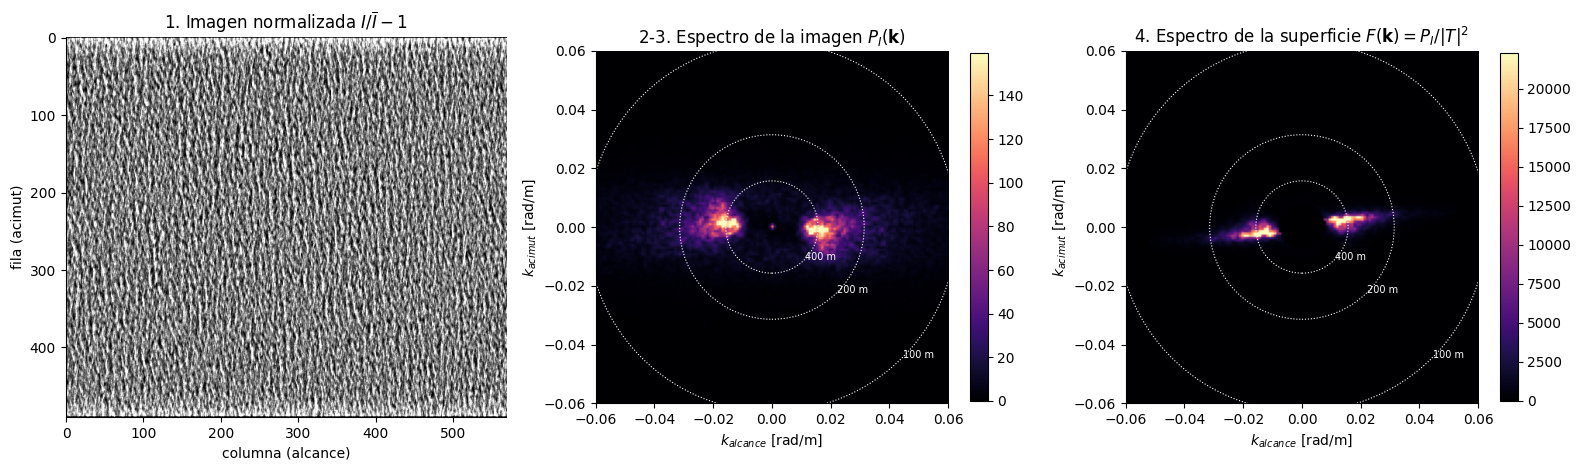

Viñeta 20160501t210028: modulación rms de la imagen = 0.30, ruido de speckle equivalente = 0.09 (desviación relativa por píxel)
Pico: λ = 428 m (T = 16.6 s, velocidad de fase 25.9 m/s, de grupo 12.9 m/s), viene de 120° o de 300° (ambigüedad de 180°), Hm0 = 7.01 m


In [24]:
k0 = 0                                           # viñeta del Océano Austral (56°S)
im0 = IMG[k0]
R0 = espectro_sar(im0["a"], im0["ec"], im0["er"], im0["sub"], im0["lon"], im0["lat"])
E0 = a_E_fth(R0, f_sar, th)
pk0 = picos_sar(R0, E0, f_sar, th)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
I_n = im0["a"] / ndimage.gaussian_filter(im0["a"], 15, mode="nearest") - 1
axs[0].imshow(I_n, cmap="gray", vmin=-0.5, vmax=0.5); axs[0].grid(False)
axs[0].set(title="1. Imagen normalizada $I/\\overline{I}-1$", xlabel="columna (alcance)", ylabel="fila (acimut)")
kmax = 0.06
ex = [R0["kc"][0], R0["kc"][-1], R0["kr"][0], R0["kr"][-1]]
for a_, M_, tit in [(axs[1], R0["dens"], "2-3. Espectro de la imagen $P_I(\\mathbf{k})$"), (axs[2], R0["F"], "4. Espectro de la superficie $F(\\mathbf{k})=P_I/|T|^2$")]:
    pc = a_.imshow(M_, origin="lower", extent=ex, cmap="magma", vmin=0, vmax=np.percentile(M_, 99.9)); a_.grid(False)
    a_.set(xlim=(-kmax, kmax), ylim=(-kmax, kmax), title=tit, xlabel="$k_{alcance}$ [rad/m]", ylabel="$k_{acimut}$ [rad/m]")
    for lam_ in (100, 200, 400):
        a_.add_patch(plt.Circle((0, 0), 2 * np.pi / lam_, fill=False, color="white", ls=":", lw=0.8))
        a_.text(2 * np.pi / lam_ * 0.71, -2 * np.pi / lam_ * 0.71, f"{lam_} m", color="white", fontsize=7)
    fig.colorbar(pc, ax=a_, shrink=0.8)
plt.tight_layout(); plt.show()
print(f"Viñeta {im0['hora']}: modulación rms de la imagen = {R0['mod_rms']:.2f}, ruido de speckle equivalente = {np.sqrt(R0['ruido'] * (2 * np.pi) ** 2 / (R0['dc'] * R0['dr'])):.2f} (desviación relativa por píxel)")
print(f"Pico: λ = {pk0['lam']:.0f} m (T = {pk0['Tp']:.1f} s, velocidad de fase {pk0['c']:.1f} m/s, de grupo {pk0['cg']:.1f} m/s), viene de {pk0['desde_a']:.0f}° o de {pk0['desde_b']:.0f}° (ambigüedad de 180°), Hm0 = {pk0['Hm0']:.2f} m")

**Lectura.** Las franjas se ven a simple vista. El espectro de la imagen tiene **dos lóbulos simétricos** (una imagen real de intensidad no distingue $\mathbf k$ de $-\mathbf k$) a unos 430 m de longitud de onda, a lo largo del eje de alcance. Al dividir por $|T|^2$ el lóbulo se estrecha y cambia de forma, porque la función de transferencia no es igual en todas las direcciones. El periodo (16,6 s) y las velocidades (unos 26 m/s de fase y 13 m/s de grupo, es decir unos 93 km/h para la fase) salen de la longitud de onda con la relación de dispersión en aguas profundas, y la altura de integrar $F$: 7 m, una pendiente $H_{m0}/\lambda\approx0{,}016$ razonable para swell desarrollado, en una zona (56°S, océano Austral en mayo) donde esas alturas son frecuentes. **No tenemos una medida independiente de esa viñeta**, así que la altura es una estimación a contrastar, no una verdad.


### Prueba con verdad conocida: escena SAR sintética

Como con la boya, antes de creer un método comprobamos que recupera una verdad que conocemos. Generamos un swell JONSWAP ($\gamma=3{,}3$, $\cos^{2s}$ con $s=40$) con 1 500 componentes de fase aleatoria, lo **pasamos por la misma función de transferencia** $T$ (con la geometría real de una viñeta) y le añadimos ruido multiplicativo de *speckle* igual al medido en las imágenes reales ($\sigma\approx0{,}087$). Luego aplicamos el mismo procesado. Ojo: la simulación usa el mismo modelo cuasi-lineal que la inversión, así que la prueba comprueba la **aritmética y la geometría** (direcciones, jacobiano, normalización), no que la física del modelo sea la correcta.

El simulador solo representa olas de más de 100 m de longitud (las que el sensor puede resolver); la columna "Hm0 visible" es la altura de esa parte del espectro.

In [25]:
def simula_sar(Hs, Tp, dir_desde, s, sub, ec, er, forma=(490, 570), n_comp=1500, sigma_ruido=0.087, semilla=0, lam_corte=100):
    # Escena SAR cuasi-lineal de un swell con verdad conocida. Devuelve la imagen y Hm0 "visible" (λ > lam_corte)
    r = np.random.default_rng(semilla); dc, dr = np.linalg.norm(ec), np.linalg.norm(er)
    fp = 1 / Tp; fg = np.linspace(0.5 * fp, 3 * fp, 4000)
    sg = np.where(fg <= fp, 0.07, 0.09)
    S = fg ** -5 * np.exp(-1.25 * (fp / fg) ** 4) * 3.3 ** np.exp(-(fg - fp) ** 2 / (2 * sg ** 2 * fp ** 2))
    S *= (Hs / 4) ** 2 / np.trapezoid(S, fg)
    cdf = np.cumsum(S); cdf /= cdf[-1]
    fj = np.interp(r.uniform(size=n_comp), cdf, fg)                                 # frecuencias con densidad S(f)
    Aj = np.sqrt(2 * (Hs / 4) ** 2 / n_comp)                                        # misma varianza por componente
    phi_to = np.deg2rad(dir_desde) + r.normal(0, np.sqrt(1 / s), n_comp) + np.pi     # cos^2s ≈ gaussiana de varianza 1/s
    kj = (2 * np.pi * fj) ** 2 / G
    ok = np.nonzero(2 * np.pi / kj > lam_corte)[0]
    kE, kN = kj * np.sin(phi_to), kj * np.cos(phi_to)
    ec_u, er_u = ec / dc, er / dr
    k_al, k_ac = kE * ec_u[0] + kN * ec_u[1], kE * er_u[0] + kN * er_u[1]            # alcance (columnas), acimut (filas)
    T = mtf(k_al, k_ac, sub); fase = r.uniform(0, 2 * np.pi, n_comp)
    # cos(k_al·c + k_ac·r + φ) = Re[e^{i k_ac r} · e^{i k_al c} · e^{iφ}]: un producto de matrices
    Ar = np.exp(1j * np.outer(np.arange(forma[0]) * dr, k_ac[ok])) * (Aj * np.abs(T[ok]) * np.exp(1j * (fase[ok] + np.angle(T[ok]))))
    Ac = np.exp(1j * np.outer(np.arange(forma[1]) * dc, k_al[ok]))
    I = 1 + (Ar @ Ac.T).real
    I = I * (1 + sigma_ruido * r.standard_normal(forma))
    return I, Hs * np.sqrt(len(ok) / n_comp)

t0 = time.time()
casos = [("swell de alcance, 3 m, 13 s", 3.0, 13, 290), ("swell oblicuo, 3 m, 13 s", 3.0, 13, 340),
         ("swell corto, 2 m, 10 s", 2.0, 10, 250), ("swell largo, 4 m, 15 s", 4.0, 15, 300),
         ("swell bajo, 1,5 m, 11 s", 1.5, 11, 110), ("swell viajando en acimut, 3 m, 13 s", 3.0, 13, 200)]
filas = []
for nombre, Hs_, Tp_, dd in casos:
    I_s, Hs_vis = simula_sar(Hs_, Tp_, dd, 40, "wv1", IMG[0]["ec"], IMG[0]["er"])
    Rs = espectro_sar(I_s, IMG[0]["ec"], IMG[0]["er"], "wv1", -120.0, -40.0)
    Es = a_E_fth(Rs, f_sar, th); ps = picos_sar(Rs, Es, f_sar, th)
    err_dir = min(abs(dif_ang(ps["desde_a"], dd)), abs(dif_ang(ps["desde_b"], dd)))
    filas.append({"caso": nombre, "Hm0 verdad [m]": Hs_, "Hm0 visible [m]": Hs_vis, "Hm0 SAR [m]": ps["Hm0"],
                  "error Hm0 vs visible [%]": 100 * (ps["Hm0"] / Hs_vis - 1), "Tp verdad [s]": Tp_, "Tp SAR [s]": ps["Tp"],
                  "dir verdad [°]": dd, "dir SAR (a o b) [°]": f"{ps['desde_a']:.0f} / {ps['desde_b']:.0f}",
                  "error dir [°]": err_dir, "modulación rms": Rs["mod_rms"]})
val_sar = pd.DataFrame(filas).set_index("caso")
display(val_sar.round(2))
print(f"tiempo: {time.time() - t0:.0f} s")

,Hm0 verdad [m],Hm0 visible [m],Hm0 SAR [m],error Hm0 vs visible [%],Tp verdad [s],Tp SAR [s],dir verdad [°],dir SAR (a o b) [°],error dir [°],modulación rms
caso,,,,,,,,,,
"swell de alcance, 3 m, 13 s",3.0,2.85,2.75,-3.57,13,12.99,290,114 / 294,3.51,0.31
"swell oblicuo, 3 m, 13 s",3.0,2.85,2.73,-4.10,13,14.08,340,158 / 338,2.18,0.84
"swell corto, 2 m, 10 s",2.0,1.71,1.61,-5.83,10,10.67,250,248 / 68,2.42,0.88
"swell largo, 4 m, 15 s",4.0,3.89,3.84,-1.30,15,15.24,300,304 / 124,4.02,0.24
"swell bajo, 1,5 m, 11 s",1.5,1.35,1.30,-3.59,11,11.60,110,109 / 289,1.04,0.19
"swell viajando en acimut, 3 m, 13 s",3.0,2.85,2.81,-1.53,13,13.02,200,23 / 203,3.08,1.22


tiempo: 2 s


**Lectura de la prueba sintética.**

* La **dirección** se recupera con 1° a 4° de error, siempre como pareja de lóbulos opuestos (a y b): el sistema no puede decir cuál de las dos es la verdadera. El **periodo** del pico cae dentro de una malla de 0,1 Hz de la verdad (el caso de 13 s con dirección oblicua da 14,1 s, un error de 8 % por la resolución de la malla de números de onda), y $H_{m0}$ sale entre un 1 % y un 6 % por debajo de la parte visible. La pérdida es un sesgo pequeño y de signo constante de la ventana espectral.
* Un **swell corto** (2 m, 10 s, λ de unos 150 m) ya pierde energía por encima de 100 m: lo que está por debajo del límite de resolución no existe en la imagen. El **mar de viento** del experimento de la boya (6,7 s, 70 m) quedaría entero fuera. Por eso el SAR da el swell y la boya el mar de viento: se complementan.
* Mira la columna **modulación rms**. Con una función de transferencia lineal, las olas oblicuas o que viajan en acimut producen en la simulación modulaciones de 0,8 a 1,2, mientras que las viñetas reales tienen entre 0,16 y 0,30. La modulación real **se satura** (el agrupamiento por velocidad deja de ser lineal y aparece el corte en acimut, que borra las olas cortas que viajan paralelas a la órbita). En la realidad, para esas direcciones, dividir por $|T|^2$ es una extrapolación fuera de su rango de validez y **subestima** la altura. La prueba solo valida la aritmética, no ese régimen.

In [26]:
filas = []
ESP_SAR = []
for k, im in enumerate(IMG):
    R_ = espectro_sar(im["a"], im["ec"], im["er"], im["sub"], im["lon"], im["lat"])
    E_ = a_E_fth(R_, f_sar, th); p_ = picos_sar(R_, E_, f_sar, th)
    ESP_SAR.append((R_, E_, p_))
    filas.append({"viñeta": f"{im['hora'][:8]} {im['hora'][9:13]}", "subfranja": im["sub"].upper(),
                  "lat [°]": im["lat"], "lon [°]": im["lon"], "λ pico [m]": p_["lam"], "Tp [s]": p_["Tp"], "c [m/s]": p_["c"], "c_g [m/s]": p_["cg"],
                  "viene de (a) [°]": p_["desde_a"], "o de (b) [°]": p_["desde_b"], "Hm0 [m]": p_["Hm0"],
                  "pendiente Hm0/λ": p_["Hm0"] / p_["lam"], "modulación rms": R_["mod_rms"]})
tab_sar = pd.DataFrame(filas).set_index("viñeta")
display(tab_sar.round(2))

# Rango de las direcciones respecto a los ejes del sensor (alcance = columnas)
az_alc = (np.rad2deg(np.arctan2(*IMG[0]["ec"])) % 180)
print(f"Eje de alcance (columnas) de la viñeta 0: {az_alc:.0f}° / {az_alc + 180:.0f}° respecto al norte")

,subfranja,lat [°],lon [°],λ pico [m],Tp [s],c [m/s],c_g [m/s],viene de (a) [°],o de (b) [°],Hm0 [m],pendiente Hm0/λ,modulación rms
viñeta,,,,,,,,,,,,
20160501 2100,WV1,-56.42,118.01,428.41,16.56,25.86,12.93,120.03,300.03,7.01,0.02,0.30
20161127 0410,WV1,-24.18,-145.99,630.10,20.09,31.37,15.68,270.16,90.16,0.97,0.00,0.19
20160614 1020,WV1,-53.24,130.22,346.39,14.89,23.26,11.63,80.74,260.74,5.91,0.02,0.29
20160127 1616,WV1,45.72,-149.30,225.16,12.01,18.75,9.37,110.01,290.01,3.58,0.02,0.27
20161010 1804,WV1,45.57,-176.09,268.75,13.12,20.48,10.24,289.63,109.63,4.30,0.02,0.27
20161224 2210,WV1,-41.54,106.96,640.74,20.26,31.63,15.81,299.96,119.96,1.58,0.00,0.23
20160108 0717,WV2,-58.51,-177.54,272.06,13.20,20.61,10.30,249.18,69.18,2.49,0.01,0.16
20160325 0053,WV2,-51.11,-86.20,308.17,14.05,21.94,10.97,253.75,73.75,3.05,0.01,0.17


Eje de alcance (columnas) de la viñeta 0: 112° / 292° respecto al norte


**Lectura de las ocho viñetas reales.**

* Los periodos van de 12 a 20 s (λ de 225 a 640 m) y $H_{m0}$ de 1,0 a 7,0 m, con las alturas mayores (6 a 7 m) en las viñetas del océano Austral entre 53°S y 56°S y las menores en latitudes subtropicales (24°S). Es un reparto razonable, aunque sin medida independiente no podemos cuantificar el error. Las pendientes $H_{m0}/\lambda$ entre 0,002 y 0,02 no tienen nada raro.
* Las dos viñetas con λ de 630 a 640 m (periodos de 20 s) caen cerca del límite de 800 m de nuestra ventana y con ventanas de 7,7 km solo caben unas 12 longitudes de onda: su periodo es menos fiable.
* Los dos valores de dirección son los dos lóbulos del mismo pico. Con la imagen sola es imposible elegir. Los productos operativos de la ESA resuelven la ambigüedad con la **fase del espectro cruzado entre dos "miradas"** del SLC complejo, que este conjunto de datos (viñetas de intensidad) no incluye.

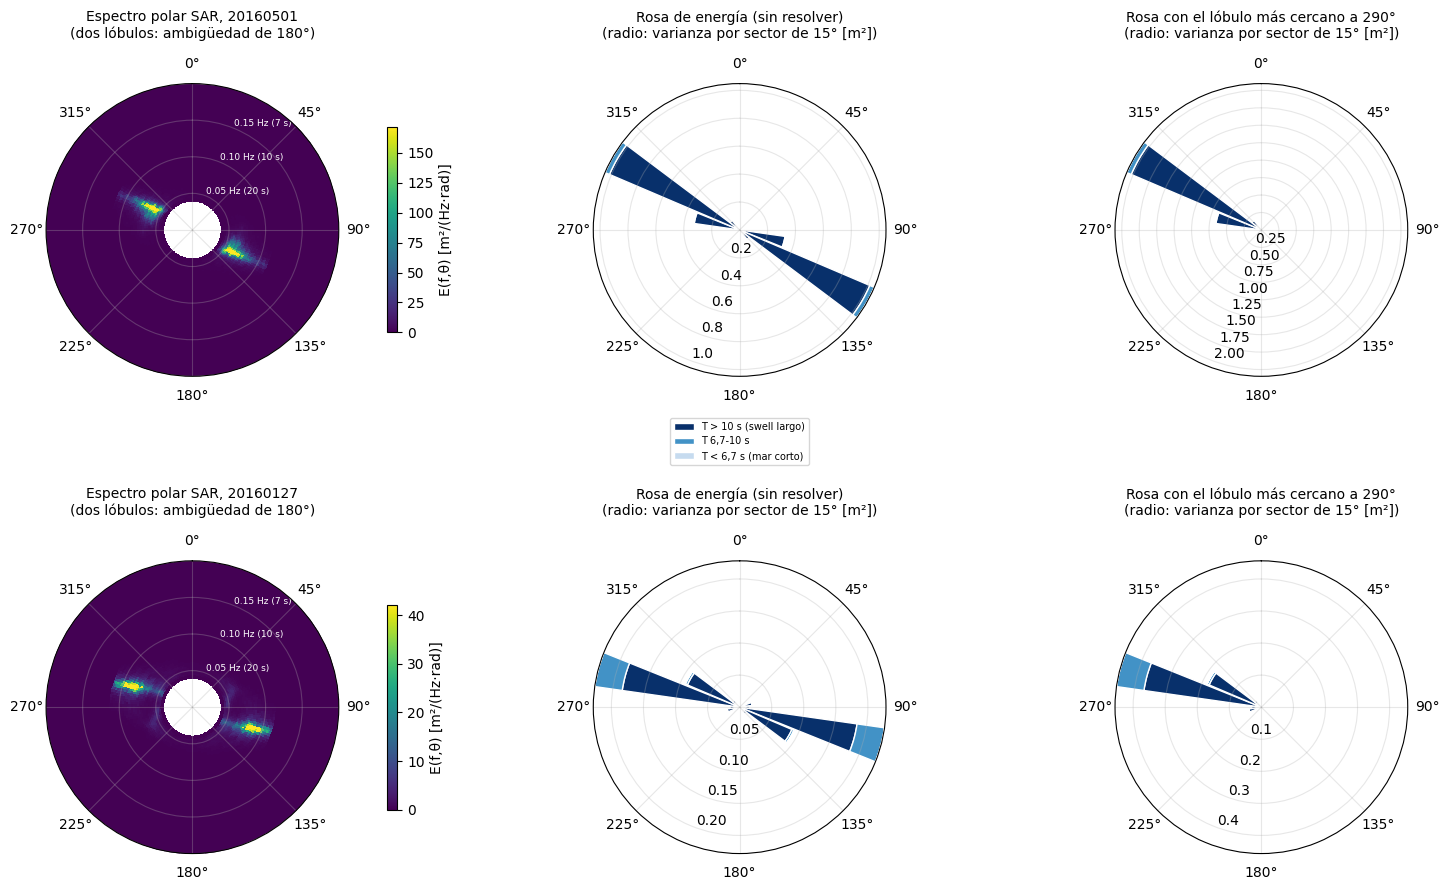

,Hm0,Tp,Te,Energia_kJm2,P_kWm
20160501,7.01,16.67,15.71,30.92,379.17
20160127,3.58,11.76,13.81,8.05,86.83


Viñeta 20160501: dirección media por banda T > 10 s, lóbulo resuelto con prior 290°: 297°
Viñeta 20160127: dirección media por banda T > 10 s, lóbulo resuelto con prior 290°: 288°


,0°,45°,90°,135°,180°,225°,270°,315°
"viñeta 20160501, % por sector",0.3,0.2,12.2,37.3,0.3,0.2,12.2,37.3
"viñeta 20160127, % por sector",0.8,2.2,33.1,13.9,0.8,2.2,33.1,13.9


In [27]:
def resuelve_ambiguedad(E_, theta, dir_ref):
    # Si se conoce de qué lado viene el swell (modelo, boya...), se conserva el lóbulo más cercano y se duplica su energía
    cerca = np.abs(dif_ang(np.rad2deg(theta), dir_ref)) < 90
    return np.where(cerca[None, :], 2 * E_, 0)

fig = plt.figure(figsize=(16, 9))
for fila, (k, dir_ref) in enumerate([(0, 290), (3, 290)]):
    R_, E_, p_ = ESP_SAR[k]; im = IMG[k]
    ax1 = fig.add_subplot(2, 3, 3 * fila + 1, projection="polar")
    pc = polar_espectro(ax1, f_sar, th, E_, vmax=np.percentile(E_, 99.8), titulo=f"Espectro polar SAR, {im['hora'][:8]}\n(dos lóbulos: ambigüedad de 180°)", fmax=0.2)
    fig.colorbar(pc, ax=ax1, shrink=0.7, pad=0.1).set_label("E(f,θ) [m²/(Hz·rad)]")
    ax2 = fig.add_subplot(2, 3, 3 * fila + 2, projection="polar")
    rosa_energia(ax2, f_sar, th, E_, titulo="Rosa de energía (sin resolver)")
    if fila == 0: ax2.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), fontsize=7)
    E_res = resuelve_ambiguedad(E_, th, dir_ref)
    ax3 = fig.add_subplot(2, 3, 3 * fila + 3, projection="polar")
    rosa_energia(ax3, f_sar, th, E_res, titulo=f"Rosa con el lóbulo más cercano a {dir_ref}°")
plt.tight_layout(); plt.show()

res_ind = pd.DataFrame({f"{IMG[k]['hora'][:8]}": indicadores(f_sar, th, ESP_SAR[k][1]) for k in (0, 3)}).T
display(res_ind.round(2))
for k in (0, 3):
    print(f"Viñeta {IMG[k]['hora'][:8]}: dirección media por banda T > 10 s, lóbulo resuelto con prior 290°:",
          f"{dir_media(f_sar, th, resuelve_ambiguedad(ESP_SAR[k][1], th, 290), ((f_sar < 0.10)[:, None] * np.ones_like(th)[None, :])):.0f}°")
display(pd.DataFrame({f"viñeta {IMG[k]['hora'][:8]}, % por sector": energia_sectores(f_sar, th, ESP_SAR[k][1]) for k in (0, 3)}).T.round(1))

**Lectura de la rosa obtenida del satélite.**

* Con las mismas funciones que la boya, la viñeta del océano Austral da $H_{m0}\approx7{,}0$ m, $T_p\approx16{,}7$ s y unos 380 kW/m de flujo de potencia, con **toda** la energía en la banda de $T>10$ s y dos lóbulos opuestos. La del Pacífico Norte (enero de 2016, 46°N) da 3,6 m, 11,8 s y unos 87 kW/m, y es en parte de la banda de 6,7 a 10 s.
* Sin información adicional la **rosa de energía** reparte la energía al 50 % entre los dos lados (por ejemplo, 37 % + 37 % en los sectores de 135° y 315°). La columna derecha supone un conocimiento externo ("el swell del Pacífico Norte en invierno viene del oeste-noroeste"): se conserva el lóbulo a menos de 90° de los 290° y se duplica su energía. En la práctica ese prior sale de un modelo de oleaje o de una boya cercana, y es la parte más débil de la cadena.
* **Las bandas de periodo corto salen vacías** (T < 6,7 s). No es que no haya mar de viento: el SAR de Sentinel-1 WV no lo ve. Por eso el $H_{m0}$ de la imagen es el del swell, y para el total hay que sumar la boya o un modelo.


## 13. Para qué sirve todo esto en un parque eólico marino

**Accesibilidad y operaciones.** Los buques de transferencia de personal (CTV) suelen operar con límites de $H_s$ en torno a 1,5 m, y los buques con pasarela compensada (SOV) hasta 2,5 a 3 m. Pero el límite real depende también del **periodo y la dirección**: un swell largo de través puede impedir una transferencia con $H_s$ moderada, y el rumbo del buque al apoyarse en la torre se elige con el espectro direccional. Los umbrales concretos varían con cada buque y procedimiento.

**Cargas de fatiga.** En un aerogenerador sobre monopilote, el rotor en marcha aporta mucho amortiguamiento aerodinámico en la dirección del viento, pero casi ninguno en la dirección lateral. Si el oleaje (sobre todo el swell) llega **desalineado** con el viento, excita la torre lateralmente con poco amortiguamiento, y el daño por fatiga crece. Por eso las bases de diseño trabajan con distribuciones conjuntas de viento, $H_s$, $T_p$ y desalineación.

**Cimentación y dinámica estructural.** La primera frecuencia propia de un aerogenerador sobre monopilote suele estar entre unos 0,2 y 0,3 Hz (periodos de 3 a 5 s), y baja a medida que las turbinas crecen. La energía del oleaje cerca de esa frecuencia (normalmente la cola del mar de viento) produce respuesta dinámica, mientras que el swell largo aporta cargas casi estáticas grandes y, por su mayor velocidad orbital cerca del fondo, influye más en la socavación y en las cargas cíclicas sobre el terreno. Saber qué sistema aporta la energía en cada banda de frecuencia ayuda a interpretar las medidas de la propia estructura.

Un indicador simple con los datos reales de la semana:

In [28]:
umbrales = [1.0, 1.5, 2.0, 2.5]
acc = pd.DataFrame({"Hs límite [m]": umbrales,
                    "tiempo accesible [%]": [100 * (serie.Hm0 < u).mean() for u in umbrales]})
display(acc.set_index("Hs límite [m]").round(0))
desal = dif_ang(serie.dir_swell, serie.WDIR).abs()
print(f"Fracción del tiempo con swell desalineado más de 45° respecto al viento: {100*(desal > 45).mean():.0f} %")
print(f"Potencia media del oleaje en la semana: {serie.P_kWm.mean():.0f} kW/m (no confundir con energía por m²)")

,tiempo accesible [%]
Hs límite [m],
1.0,0.0
1.5,4.0
2.0,12.0
2.5,23.0


Fracción del tiempo con swell desalineado más de 45° respecto al viento: 58 %
Potencia media del oleaje en la semana: 80 kW/m (no confundir con energía por m²)



## 14. Limitaciones, y dónde entrarían las GNN y las PINN

**Lo que hay que tener presente**

* **Resolución direccional de una boya:** cuatro coeficientes por frecuencia. Dos sistemas a la misma frecuencia con direcciones distintas no se resuelven bien con ningún método. Los arrays de sensores, radares de banda X o HF (alta frecuencia) y satélites dan más grados de libertad.
* **Elección del método:** MEM da picos estrechos (a veces demasiado) y lóbulos espurios; Fourier truncado es ancho y con negativos; MLM está en medio. Ninguno es "la verdad": todos son reconstrucciones compatibles con los mismos 4 números.
* **Ruido y estadística:** con 20 a 60 minutos de registro, $S(f)$ tiene incertidumbre de muestreo y la estimación de dirección se degrada en frecuencias con poca energía. El ruido de las pendientes hace el mar más isótropo de lo que es.
* **Un punto, no un campo:** la boya describe el oleaje en un punto. En un parque de decenas de km² con batimetría variable, el espectro cambia de una turbina a otra.
* **Hipótesis lineales y aguas profundas:** las fórmulas usadas suponen ondas lineales; en aguas someras hay que usar la relación de dispersión completa y la potencia cambia con $c_g$.
* **Separación mar de viento / swell:** depende de $\beta$, del viento corregido a 10 m y del criterio (1D, 2D o particiones).
* **Oleaje desde satélite (SAR):** solo longitudes de onda de más de unos 100 a 120 m (el mar de viento queda fuera), ambigüedad de 180° con imágenes de intensidad, un corte en acimut que borra las olas cortas que viajan paralelas a la órbita, y una altura que depende de una función de transferencia cuasi-lineal sin modulación hidrodinámica. La altura que sale aquí **no está validada con medidas independientes**; los productos operativos la calibran con boyas y modelos. El siguiente paso razonable es una **red convolucional** (PyTorch) entrenada con viñetas colocalizadas con boyas o con reanálisis para estimar $H_s$ directamente de la imagen (el cuaderno 05 lo hace con datos sintéticos y deja el plan de validación con ERA5; el 04 explica cuándo PyTorch aporta frente a XGBoost).

**Lectura para continuar (sin implementar aquí)**

* **Redes neuronales de grafos (GNN):** varias boyas, radares o puntos de modelo pueden verse como nodos de un grafo, con aristas según distancia y dirección de propagación. Una GNN puede aprender a propagar o interpolar espectros entre puntos (por ejemplo, de una boya exterior a las posiciones de las turbinas). El reto es disponer de suficientes estaciones y de datos de validación.
* **Redes neuronales informadas por la física (PINN):** la evolución de $E(f,\theta)$ en el espacio y el tiempo la gobierna la ecuación de balance de acción espectral, $N = E/\sigma$,
$$
\frac{\partial N}{\partial t} + \nabla_{\mathbf{x}}\cdot(\mathbf{c}_g N) + \frac{\partial (c_\sigma N)}{\partial \sigma} + \frac{\partial (c_\theta N)}{\partial \theta} = \frac{S_{in} + S_{nl} + S_{ds} + \dots}{\sigma},
$$
que resuelven los modelos espectrales de tercera generación. Una PINN puede usar esa ecuación como término de pérdida para rellenar el campo entre medidas dispersas. Es un área de investigación activa: los términos fuente son empíricos y el coste de entrenamiento es alto.

**Referencias**

* Longuet-Higgins, M. S., Cartwright, D. E. y Smith, N. D. (1963). *Observations of the directional spectrum of sea waves using the motions of a floating buoy*. Ocean Wave Spectra, Prentice-Hall, 111-136. [Ficha en CiNii](https://cir.nii.ac.jp/crid/1570291225447611392) (no se ha encontrado un PDF abierto).
* Lygre, A. y Krogstad, H. E. (1986). *Maximum entropy estimation of the directional distribution in ocean wave spectra*. Journal of Physical Oceanography, 16, 2052-2060. [doi:10.1175/1520-0485(1986)016<2052:MEEOTD>2.0.CO;2](https://doi.org/10.1175/1520-0485(1986)016%3C2052:MEEOTD%3E2.0.CO;2).
* Earle, M. D. (1996). *Nondirectional and directional wave data analysis procedures*. NDBC Technical Document 96-01. [PDF (copia archivada de NOAA/NDBC)](https://webarchive.library.unt.edu/eot2008/20090116205730/http:/www.ndbc.noaa.gov/wavemeas.pdf).
* Hasselmann, K. et al. (1973). *Measurements of wind-wave growth and swell decay during the Joint North Sea Wave Project (JONSWAP)*. Deutsche Hydrographische Zeitschrift, Reihe A, 8(12). [PDF](https://airsea.ucsd.edu/wp-content/uploads/sites/10/2019/10/Jonswap-Hasselmann1973.pdf).
* Holthuijsen, L. H. (2007). *Waves in Oceanic and Coastal Waters*. Cambridge University Press. [doi:10.1017/CBO9780511618536](https://doi.org/10.1017/CBO9780511618536) (de pago).
* Wang, C., Mouche, A., Tandeo, P. et al. (2019). *A labelled ocean SAR imagery dataset of ten geophysical phenomena from Sentinel-1 wave mode*. Geoscience Data Journal, 6(2), 105-115. [Artículo (doi:10.1002/gdj3.73)](https://doi.org/10.1002/gdj3.73). Datos: [doi:10.17882/56796](https://doi.org/10.17882/56796), [SEANOE](https://www.seanoe.org/data/00456/56796/) (CC BY-NC-SA 4.0).
* Alpers, W. R., Ross, D. B. y Rufenach, C. L. (1981). *On the detectability of ocean surface waves by real and synthetic aperture radar*. Journal of Geophysical Research, 86(C7), 6481-6498. [doi:10.1029/JC086iC07p06481](https://doi.org/10.1029/JC086iC07p06481).
* Hasselmann, K. y Hasselmann, S. (1991). *On the nonlinear mapping of an ocean wave spectrum into a synthetic aperture radar image spectrum*. Journal of Geophysical Research, 96(C6), 10713-10729. [doi:10.1029/91JC00302](https://doi.org/10.1029/91JC00302).
* Quach, B., Glaser, Y., Stopa, J. E., Mouche, A. A. y Sadowski, P. (2021). *Deep learning for predicting significant wave height from synthetic aperture radar*. IEEE Transactions on Geoscience and Remote Sensing, 59(3), 1859-1867 (publicado en línea en 2020). [doi:10.1109/TGRS.2020.3003839](https://doi.org/10.1109/TGRS.2020.3003839).
* Datos de boya: NOAA National Data Buoy Center, [estación 46042](https://www.ndbc.noaa.gov/station_page.php?station=46042).

In [29]:
print(f"Tiempo total de ejecución del notebook: {time.time() - t_inicio:.0f} s")

Tiempo total de ejecución del notebook: 102 s
